# 📈 Sistem Pakar: Prediksi Waktu *Buy / Sell / Hold* Saham Berdasarkan Berita Ekonomi
**Final Exam – Mini Project & Reporting (UKRIDA)** · Topik: *Predicting when to buy or sell stocks based on economic news*

Notebook ini berisi **program lengkap** + bahan **laporan** (flowchart, arsitektur sistem, knowledge base, minimum 20 test case).

| Komponen | Isi |
|---|---|
| Dataset | `IndianFinancialNews.csv` — 50.000 artikel berita keuangan India (Feb 2003 – Mei 2020; kolom `Date`, `Title`, `Description`) + harga penutupan indeks saham India (`CP`) yang ditarik otomatis dari **Yahoo Finance (`yfinance`)** |
| Metode | *Rule-based expert system* (forward chaining + **Certainty Factor** MYCIN) dengan input sentimen berita berbasis kamus & aspek (teks = `Title` + `Description`) |
| Output | Rekomendasi **BUY / SELL / HOLD** + penjelasan aturan mana yang aktif |

### Bagaimana 3 referensi dipakai
| Referensi | Dipakai untuk |
|---|---|
| **Barbaglia, Consoli & Manzan (2022)** – *Forecasting with Economic News* | Ide *Fine-Grained Aspect-Based Sentiment (FiGAS)*: kamus sentimen berskala **[-1, +1]**, *Token of Interest* (ekonomi, sektor keuangan, inflasi, manufaktur, kebijakan moneter, pengangguran), penanganan negasi. |
| **Maghyereh & Abdoh (2022)** – *Can news-based economic sentiment predict bubbles in precious metal markets?* | Landasan aturan pakar: sentimen sangat bearish → peluang kontrarian, euforia + harga jenuh → risiko *bubble*, kebijakan moneter longgar → aset berisiko naik, pengaruh inflasi & suku bunga. |
| **Dornadula et al. (2023)** – *Survey of COVID-19 Detection from Chest X-Rays* | Bukan domain yang sama; dipakai untuk **metodologi evaluasi** (accuracy, precision, recall, F1, confusion matrix), perbandingan dengan model ML lain, serta diskusi keterbatasan (data kecil, overfitting, generalisasi). |

> 🔧 **Adaptasi dataset (versi India):** arsitektur model, metode sistem pakar (forward chaining + CF MYCIN), logika FiGAS, dan 16 aturan **tidak diubah**. Yang disesuaikan hanya: (1) pipeline data (parsing tanggal, `Title`+`Description`, harga `yfinance`, fitur teknikal dihitung ulang), (2) kamus/ToI ditambah istilah keuangan India (RBI, repo rate, Sensex, Nifty, dst.), (3) pembagian waktu: train 2003–2014, test 2015–Mei 2020 (data uji ±1.300 hari agar hasil lebih stabil), (4) **kalibrasi ulang parameter** (ambang fuzzifikasi sentimen & bobot CF) pada **data latih saja**, divalidasi sebelum dipakai (bagian 6.0). Struktur 16 aturan dan kondisi IF–THEN tidak diubah.
>
> ⚠️ **Catatan penting:** ini proyek akademik. Hasil bukan saran investasi.

## 1. Setup & Memuat Dataset

In [1]:
import os, re, math, glob, zipfile, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, Polygon, FancyArrowPatch
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix,
                             precision_recall_fscore_support, ConfusionMatrixDisplay)
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from IPython.display import display
try:
    import yfinance as yf
except ImportError:            # Colab / lingkungan baru
    import subprocess, sys
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', 'yfinance'])
    import yfinance as yf

warnings.filterwarnings("ignore")
pd.set_option("display.width", 200); pd.set_option("display.max_colwidth", 90)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .25})
os.makedirs("figs", exist_ok=True)

# ---------------- KONFIGURASI ----------------
CSV_NAME     = "IndianFinancialNews.csv"
INDEX_TICKER = "^BSESN"          # BSE Sensex (data Yahoo sejak 1997 → menutup seluruh 2003–2020). Alternatif: "^NSEI" (Nifty 50, data Yahoo baru sejak Sep 2007)
SPLIT_DATE   = "2015-01-01"      # train: sebelum tanggal ini | test: sejak tanggal ini (±5,4 tahun: demonetisasi 2016, krisis NBFC 2018, crash COVID-19 Mar 2020)
VALID_START  = "2012-01-01"      # di dalam train: 2003–2011 = "fit" (kalibrasi), 2012–2014 = validasi (memilih apakah kalibrasi dipakai)
LABEL_THR    = 0.005             # BUY jika return berikutnya > +0.5%, SELL jika < -0.5% (sama seperti notebook asli)
MA_WINDOW, VOL_WINDOW = 20, 20   # tren = CP/MA-20 − 1 ; volatilitas = std return harian 20 hari

def find_dataset():
    """Cari CSV di folder kerja / zip / Colab / folder upload."""
    if os.path.exists(CSV_NAME): return CSV_NAME
    for folder in [".", "/content", "/mnt/user-data/uploads", "data"]:
        for z in glob.glob(os.path.join(folder, "*.zip")):
            try:
                with zipfile.ZipFile(z) as zf:
                    if CSV_NAME in zf.namelist():
                        zf.extract(CSV_NAME, "."); return CSV_NAME
            except zipfile.BadZipFile: pass
        p = os.path.join(folder, CSV_NAME)
        if os.path.exists(p): return p
    try:   # Google Colab: upload manual
        from google.colab import files
        print("Dataset tidak ditemukan, silakan upload IndianFinancialNews.csv.zip / CSV ...")
        up = files.upload()
        for name in up:
            if name.endswith(".zip"):
                with zipfile.ZipFile(name) as zf: zf.extract(CSV_NAME, ".")
        return CSV_NAME
    except ImportError:
        raise FileNotFoundError(f"Letakkan {CSV_NAME} (atau IndianFinancialNews.csv.zip) di folder yang sama dengan notebook ini.")

df = pd.read_csv(find_dataset())
df = df[[c for c in ["Date", "Title", "Description"] if c in df.columns]]
# Tanggal berformat "May 26, 2020, Tuesday"
d_raw = df["Date"].astype(str)
df["Date"] = pd.to_datetime(d_raw, format="%B %d, %Y, %A", errors="coerce")
bad = df["Date"].isna()
if bad.any():                                   # cadangan untuk format tanggal lain
    df.loc[bad, "Date"] = pd.to_datetime(d_raw[bad], errors="coerce")
df = df.dropna(subset=["Date", "Title"]).copy()
df["Title"]       = df["Title"].astype(str).str.strip()
df["Description"] = df["Description"].fillna("").astype(str).str.strip()
# >>> TEKS INPUT FiGAS = Title + Description <<<
same = df["Description"].str.lower().eq(df["Title"].str.lower()) | df["Description"].eq("")   # Deskripsi kosong / identik dgn judul (umum di 2003) → jangan dihitung dua kali
df["Text"] = np.where(same, df["Title"], (df["Title"] + ". " + df["Description"]).str.strip(" .") + ".")
n_raw = len(df)
df = df.drop_duplicates(["Title", "Date"]).sort_values("Date").reset_index(drop=True)   # artikel yang sama pada hari yang sama dihitung sekali
print(f"Duplikat dibuang : {n_raw-len(df)} baris")
print("Ukuran data :", df.shape)
print("Rentang     :", df.Date.min().date(), "→", df.Date.max().date())
print("Hari kalender unik:", df.Date.nunique(), "| Deskripsi kosong/sama dgn judul (hanya Title dipakai):", int(same.sum()))
df[["Date", "Title", "Description", "Text"]].head()

Duplikat dibuang : 583 baris
Ukuran data : (49417, 4)
Rentang     : 2003-02-10 → 2020-05-26
Hari kalender unik: 6068 | Deskripsi kosong/sama dgn judul (hanya Title dipakai): 2047


,Date,Title,Description,Text
0,2003-02-10,Sticky Loans Divide Consortiums,Sticky Loans Divide Consortiums,Sticky Loans Divide Consortiums
1,2003-02-10,Rbi Calls Meet To Push Floating Rate Deposits,Rbi Calls Meet To Push Floating Rate Deposits,Rbi Calls Meet To Push Floating Rate Deposits
2,2003-02-10,"Net Scheduled Inflows Of Rs 1,559.9 Crore","Net Scheduled Inflows Of Rs 1,559.9 Crore","Net Scheduled Inflows Of Rs 1,559.9 Crore"
3,2003-02-11,Crisil Scripts Risk Gauge Tool For Film Industry,Crisil Scripts Risk Gauge Tool For Film Industry,Crisil Scripts Risk Gauge Tool For Film Industry
4,2003-02-11,Banks Plan To Raise Lending Rates Without Altering Plrs,Banks Plan To Raise Lending Rates Without Altering Plrs,Banks Plan To Raise Lending Rates Without Altering Plrs


### 1.1 Harga historis indeks saham India (`yfinance`) & fitur teknikal
Dataset berita **tidak memuat harga**, sehingga `CP` (Closing Price) diambil dari Yahoo Finance untuk indeks acuan (`INDEX_TICKER`, default **BSE Sensex `^BSESN`**; ganti ke `"^NSEI"` untuk Nifty 50).

**Pencocokan tanggal berita ↔ harga:** berita bertanggal *t* dipasangkan dengan hari bursa **pertama pada/setelah t** (berita akhir pekan/hari libur → sesi bursa berikutnya). Harga pada hari itu adalah informasi yang sudah ada saat berita terbit, sehingga **tidak ada kebocoran masa depan**.

**Fitur teknikal** (dihitung dari deret harga hari bursa lengkap, hanya memakai data hari *t* dan sebelumnya):
| Fitur | Definisi |
|---|---|
| `CP` | harga penutupan indeks |
| `ret_1` | return harian `CP_t / CP_{t-1} − 1` |
| `trend` | `CP / MA-20 − 1` |
| `vol` | simpangan baku `ret_1` 20 hari terakhir |
| `ret_next` | return hari bursa berikutnya `CP_{t+1}/CP_t − 1` (**target/label**, bukan fitur) |

> Hasil unduhan disimpan ke file cache CSV; jika Yahoo gagal diakses tetapi cache ada, cache dipakai.

In [2]:
PRICE_CACHE = f"harga_{INDEX_TICKER.strip('^')}.csv"

def load_prices(ticker, start, end, cache=PRICE_CACHE):
    """Ambil harga penutupan harian (Close, tidak disesuaikan) dari Yahoo Finance; simpan/pakai cache CSV."""
    if os.path.exists(cache):
        p = pd.read_csv(cache, parse_dates=["Date"]).set_index("Date")["Close"]
        if p.index.min() <= pd.Timestamp(start) + pd.Timedelta(days=10) and p.index.max() >= pd.Timestamp(end) - pd.Timedelta(days=10):
            print(f"Memakai cache harga: {cache}"); return p
    try:
        h = yf.Ticker(ticker).history(start=start, end=end, auto_adjust=False)["Close"]
        if h.empty: raise RuntimeError("Yahoo mengembalikan data kosong")
    except Exception as e:
        print("Ticker().history gagal →", repr(e)[:120], "| mencoba yf.download ...")
        h = yf.download(ticker, start=start, end=end, auto_adjust=False, progress=False)["Close"]
        if isinstance(h, pd.DataFrame): h = h.iloc[:, 0]
        if h.empty: raise RuntimeError(f"Tidak bisa mengunduh {ticker}. Periksa koneksi internet / ganti INDEX_TICKER.")
    h.index = pd.to_datetime(h.index).tz_localize(None).normalize()
    h = h.dropna().sort_index(); h = h[~h.index.duplicated()]
    h.rename("Close").rename_axis("Date").to_csv(cache)
    print(f"Harga diunduh dari Yahoo Finance & disimpan ke {cache}")
    return h

start = df.Date.min() - pd.Timedelta(days=60)      # 60 hari ekstra untuk pemanasan MA-20 / volatilitas
end   = df.Date.max() + pd.Timedelta(days=15)      # beberapa hari ekstra agar ret_next hari terakhir terhitung
px = load_prices(INDEX_TICKER, start.strftime("%Y-%m-%d"), end.strftime("%Y-%m-%d")).to_frame("CP")

# ---- fitur teknikal pada seluruh hari bursa ----
px["ret_1"]    = px.CP.pct_change()
px["trend"]    = px.CP / px.CP.rolling(MA_WINDOW,  min_periods=5).mean() - 1      # tren vs MA-20
px["vol"]      = px.ret_1.rolling(VOL_WINDOW, min_periods=5).std()                # volatilitas 20 hari
px["ret_next"] = px.CP.shift(-1) / px.CP - 1                                      # return hari bursa berikutnya (target)
px.index.name = "TDate"
print(f"{INDEX_TICKER}: {len(px)} hari bursa | {px.index.min().date()} → {px.index.max().date()}")

# ---- cocokkan tanggal berita → hari bursa pertama pada/setelah tanggal berita ----
cal = px.reset_index()[["TDate"]]
df = pd.merge_asof(df.sort_values("Date"), cal, left_on="Date", right_on="TDate", direction="forward", tolerance=pd.Timedelta(days=10))
n_unmatched = int(df.TDate.isna().sum()); df = df.dropna(subset=["TDate"]).reset_index(drop=True)
print(f"Berita terpasang ke hari bursa: {len(df)} | tidak terpasang (di luar rentang harga): {n_unmatched}")
print(f"Berita pada hari non-bursa (akhir pekan/libur) yang digeser ke sesi berikutnya: {(df.Date != df.TDate).mean():.1%}")
px.tail()

Harga diunduh dari Yahoo Finance & disimpan ke harga_BSESN.csv
^BSESN: 4300 hari bursa | 2002-12-12 → 2020-06-09
Berita terpasang ke hari bursa: 49417 | tidak terpasang (di luar rentang harga): 0
Berita pada hari non-bursa (akhir pekan/libur) yang digeser ke sesi berikutnya: 20.0%


,CP,ret_1,trend,vol,ret_next
TDate,,,,,
2020-06-03,34109.539062,0.008396,0.078289,0.016643,-0.003777
2020-06-04,33980.699219,-0.003777,0.070333,0.016718,0.009021
2020-06-05,34287.238281,0.009021,0.075173,0.016540,0.002431
2020-06-08,34370.578125,0.002431,0.073197,0.016540,-0.012042
2020-06-09,33956.691406,-0.012042,0.056323,0.016878,NaN


## 2. Eksplorasi Data (EDA)
Dua hal penting: (1) jumlah artikel per tahun **tidak merata** (puncak 2009–2010, turun setelah 2014), (2) `CP` adalah harga penutupan indeks saham India (dari `yfinance`) pada hari bursa yang dipasangkan dengan berita.

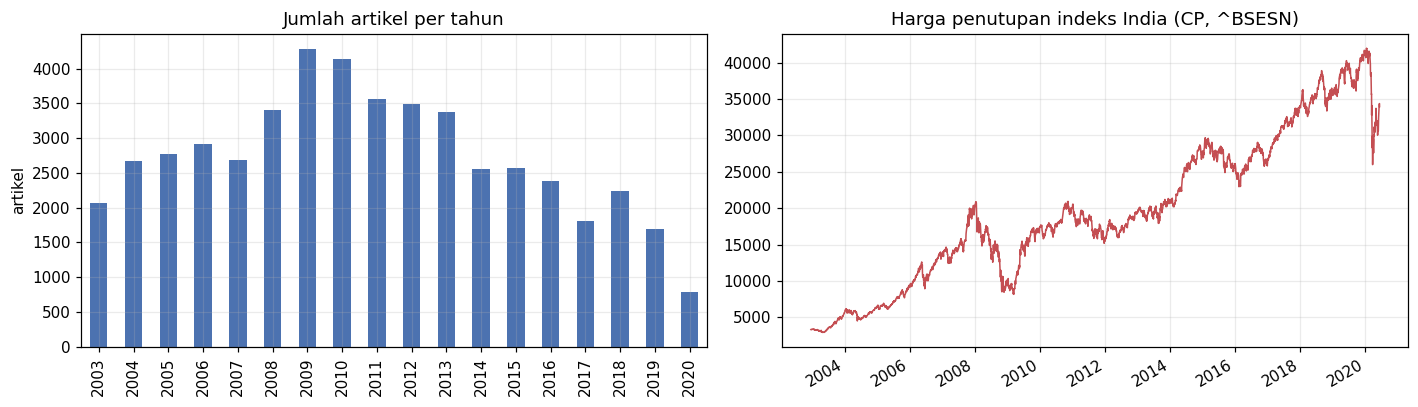

Missing value (setelah pembersihan):
 Date             0
Title            0
Description    725
Text             0
Panjang teks gabungan (kata): rata-rata 26.3 | maks 44


In [3]:
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
df.groupby(df.Date.dt.year).size().plot.bar(ax=ax[0], color="#4C72B0")
ax[0].set_title("Jumlah artikel per tahun"); ax[0].set_xlabel(""); ax[0].set_ylabel("artikel")
px.CP.plot(ax=ax[1], color="#C44E52", lw=1); ax[1].set_title(f"Harga penutupan indeks India (CP, {INDEX_TICKER})"); ax[1].set_xlabel("")
plt.tight_layout(); plt.savefig("figs/eda.png"); plt.show()
print("Missing value (setelah pembersihan):\n", df[["Date","Title","Description","Text"]].replace("", np.nan).isna().sum().to_string())
print("Panjang teks gabungan (kata): rata-rata", round(df.Text.str.split().str.len().mean(), 1), "| maks", df.Text.str.split().str.len().max())

## 3. Modul Sentimen Berita (terinspirasi FiGAS)
Langkah per teks (**`Title` + `Description`** digabung menjadi satu teks input):
1. **Normalisasi & frasa** – `"rate cut"` → `ratecut`, `"bear market"` → `bearmarket`, dst.
2. **Skor kata** dari kamus ekonomi-keuangan (rentang **−1…+1**, ide Barbaglia et al. yang mengembangkan kamus Loughran-McDonald).
3. **Modifikasi**: *intensifier* (sharply, biggest ×1.3–1.5), *dampener* (slightly ×0.6), **negasi** (not, no → ×−0.8).
4. **Aspect-based**: hanya kata di sekitar **Token of Interest** (jendela ±5 kata, bobot 1/(1+jarak)) yang dihitung untuk aspek tsb.
5. **Pembalikan polaritas** untuk ToI tertentu: *"unemployment **falls**"* = baik, *"inflation **rises**"* = buruk.

> **Penyesuaian India:** kamus/ToI ditambah istilah keuangan India (RBI/Reserve Bank of India, repo rate, MPC, CRR/SLR, Sensex, Nifty, FII/FPI, NPA, SEBI, rupee, dst.) — lihat dict `INDIA_*` di bawah. Mekanisme FiGAS tidak diubah.

> **Penyederhanaan jujur:** paper aslinya memakai *dependency parsing* spaCy (aturan `amod`, `dobj`, dst.). Di sini dipakai jendela kata agar notebook ringan dan tanpa unduhan model bahasa.

In [4]:
LEXICON = {
 # --- positif ---
 'rally':.6,'rallies':.6,'rallied':.6,'surge':.7,'surges':.7,'surged':.7,'soar':.8,'soars':.8,'soared':.8,'jump':.5,'jumps':.5,'jumped':.5,
 'gain':.5,'gains':.5,'gained':.5,'rise':.4,'rises':.4,'rose':.4,'rising':.4,'climb':.5,'climbs':.5,'climbed':.5,'higher':.4,'up':.2,
 'advance':.4,'advances':.4,'record':.5,'boom':.7,'booming':.7,'strong':.5,'stronger':.6,'strength':.5,'robust':.6,'upbeat':.6,
 'optimism':.6,'optimistic':.6,'bullish':.7,'bull':.5,'recovery':.6,'recover':.5,'recovers':.5,'rebound':.6,'rebounds':.6,'growth':.5,
 'expansion':.5,'expand':.4,'profit':.5,'profits':.5,'beat':.4,'beats':.4,'upgrade':.5,'upgrades':.5,'confidence':.4,'improve':.5,'improves':.5,
 'improved':.5,'improving':.5,'stimulus':.5,'easing':.4,'cut':.1,'cuts':.1,'positive':.4,'resilient':.5,'resilience':.5,'boost':.5,'boosts':.5,
 'opportunity':.4,'opportunities':.4,'hope':.3,'hopes':.3,'buy':.3,'outperform':.5,'calm':.3,'relief':.5,'lift':.4,'lifts':.4,'steady':.2,
 'stable':.3,'stabilize':.4,'stabilizes':.4,'upside':.5,'winners':.4,'winner':.4,'breakout':.5,'healthy':.5,'cheer':.4,'cheers':.4,
 # --- negatif ---
 'plunge':-.8,'plunges':-.8,'plunged':-.8,'crash':-.9,'crashes':-.9,'crashed':-.9,'collapse':-.9,'collapses':-.9,'tumble':-.7,'tumbles':-.7,
 'tumbled':-.7,'slump':-.7,'slumps':-.7,'sink':-.6,'sinks':-.6,'sank':-.6,'drop':-.5,'drops':-.5,'dropped':-.5,'fall':-.5,'falls':-.5,'fell':-.5,
 'falling':-.5,'decline':-.5,'declines':-.5,'declined':-.5,'lower':-.4,'down':-.2,'loss':-.5,'losses':-.5,'lose':-.5,'loses':-.5,'lost':-.5,
 'slide':-.5,'slides':-.5,'slid':-.5,'sell-off':-.7,'selloff':-.7,'selling':-.3,'sell':-.3,'weak':-.5,'weaker':-.6,'weakness':-.5,'fear':-.6,'fears':-.6,
 'worry':-.5,'worries':-.5,'worried':-.5,'concern':-.4,'concerns':-.4,'anxiety':-.5,'panic':-.9,'crisis':-.8,'recession':-.8,'recessions':-.8,
 'bear':-.5,'bearish':-.7,'pessimism':-.6,'pessimistic':-.6,'slowdown':-.6,'slowing':-.5,'slow':-.3,'contraction':-.6,'shrink':-.5,'shrinks':-.5,
 'downgrade':-.5,'downgrades':-.5,'miss':-.4,'misses':-.4,'risk':-.3,'risks':-.3,'risky':-.4,'volatile':-.4,'volatility':-.3,'turmoil':-.7,'trouble':-.5,
 'troubles':-.5,'default':-.7,'bankruptcy':-.8,'bankrupt':-.8,'layoffs':-.5,'layoff':-.5,'fraud':-.7,'warning':-.5,'warns':-.5,'warn':-.5,'threat':-.5,
 'threatens':-.5,'uncertainty':-.5,'uncertain':-.4,'negative':-.4,'bubble':-.5,'overvalued':-.5,'correction':-.5,'downside':-.5,'losers':-.4,'stagnant':-.4,
 'struggle':-.5,'struggles':-.5,'pressure':-.3,'shock':-.6,'inflationary':-.3,'dismal':-.7,'grim':-.6,'worst':-.8,'worse':-.6,'hike':-.2,'hikes':-.2,
 'rout':-.8,'spook':-.5,'wipeout':-.8,'wipes':-.5,'tank':-.7,'tanks':-.7,'deteriorate':-.6,'deteriorating':-.6,'sluggish':-.4,'spooks':-.5,'jitters':-.4,
 'fail':-.6,'fails':-.6,'failed':-.6,'failure':-.7,'freeze':-.5,
}
PHRASES = {
 'rate cut':'ratecut','rate cuts':'ratecut','cuts rates':'ratecut','cut rates':'ratecut','lower rates':'ratecut','lowers rates':'ratecut',
 'rate hike':'ratehike','rate hikes':'ratehike','raises rates':'ratehike','raise rates':'ratehike','higher rates':'ratehike','hikes rates':'ratehike',
 'bear market':'bearmarket','bull market':'bullmarket','sell off':'sell-off','all-time high':'record','all time high':'record','record high':'record',
 'job cuts':'layoffs','job losses':'layoffs','jobs added':'jobgain','job gains':'jobgain','beats expectations':'beat','misses expectations':'miss',
 'better than expected':'beat','worse than expected':'miss',
}
LEXICON.update({'ratecut':.5,'ratehike':-.5,'bearmarket':-.7,'bullmarket':.7,'jobgain':.5})
INTENSIFIERS = {'sharply':1.5,'sharp':1.4,'steeply':1.5,'deeply':1.4,'massive':1.5,'biggest':1.4,'worst':1.0,'huge':1.4,'more':1.2,'very':1.3,'extremely':1.5,'record':1.0,'rapid':1.4,'severe':1.4}
DAMPENERS   = {'slightly':0.6,'modestly':0.6,'little':0.6,'mildly':0.6,'marginally':0.5,'slight':0.6,'small':0.7}
NEGATIONS   = {'not','no','never','without',"n't",'nor','neither','avoid','avoids','averts','avert'}

# Tokens of Interest (ToI) per aspek – ide dari FiGAS (Barbaglia et al., 2022) + aspek 'market' untuk saham
ASPECTS = {
 'economy':       ['economy','economic','gdp','growth','consumer','spending','retail','housing'],
 'financial':     ['bank','banks','banking','lender','lending','credit','bond','bonds','treasury','yield','yields','financial','insurer','mortgage','debt'],
 'inflation':     ['inflation','prices','cpi','ppi','costs'],
 'manufacturing': ['manufacturing','factory','industrial','production','output','auto','ism','durable'],
 'monetary':      ['fed','federal','rates','rate','ratecut','ratehike','bernanke','powell','yellen','ecb','central','monetary','fomc','easing','tightening'],
 'unemployment':  ['unemployment','claims','jobs','job','payrolls','payroll','hiring','jobless','employment','layoffs','jobgain','labor'],
 'market':        ['stocks','stock','market','markets','dow','nasdaq','s&p','wall','equities','shares','index','indexes','indices'],
}
# ---------- PENAMBAHAN ISTILAH KEUANGAN INDIA (adaptasi dataset; mekanisme FiGAS tetap) ----------
INDIA_PHRASES = {
 'reserve bank of india':'rbi', 'reserve bank':'rbi', 'monetary policy committee':'mpc',
 'repo rate cut':'ratecut', 'cuts repo rate':'ratecut', 'cut repo rate':'ratecut', 'cut in repo rate':'ratecut', 'slashes repo rate':'ratecut',
 'cuts policy rate':'ratecut', 'cuts key rates':'ratecut', 'cuts crr':'ratecut', 'reduces repo rate':'ratecut', 'lowers repo rate':'ratecut',
 'repo rate hike':'ratehike', 'hikes repo rate':'ratehike', 'raises repo rate':'ratehike', 'hike in repo rate':'ratehike', 'hikes policy rate':'ratehike',
 'bad loans':'npa', 'non-performing assets':'npa', 'non performing assets':'npa', 'gross npa':'npa',
 'foreign institutional investors':'fii', 'foreign portfolio investors':'fpi',
}
PHRASES.update(INDIA_PHRASES)
LEXICON.update({
 'scam':-.7, 'scams':-.7, 'npa':-.4, 'npas':-.4, 'lockdown':-.5, 'coronavirus':-.5, 'covid':-.4, 'pandemic':-.6, 'bailout':-.4,
 'moratorium':-.3, 'defaults':-.7, 'defaulted':-.7, 'downgraded':-.5, 'upgraded':.5, 'revival':.5, 'reform':.4, 'reforms':.4,
 'surplus':.4, 'deficit':-.4, 'outflow':-.4, 'outflows':-.4, 'inflow':.4, 'inflows':.4, 'bumper':.5, 'slashed':-.3, 'dips':-.4, 'dip':-.4,
})
INDIA_ASPECTS = {
 'monetary':     ['rbi','repo','mpc','crr','slr','rajan','subbarao','shaktikanta','policy'],       # RBI / kebijakan moneter
 'financial':    ['npa','npas','sebi','irdai','nbfc','nbfcs','lender','lenders','deposits','loans'],
 'inflation':    ['wpi'],
 'economy':      ['rupee','fdi','budget','fiscal','exports','imports'],
 'market':       ['sensex','nifty','bse','nse','fii','fiis','fpi','fpis','ipo','ipos','bourses'],
}
for _a, _ws in INDIA_ASPECTS.items(): ASPECTS[_a] = ASPECTS[_a] + [w for w in _ws if w not in ASPECTS[_a]]
TOI2ASPECT = {w: a for a, ws in ASPECTS.items() for w in ws}
WINDOW = 5
DIRECTION = {'rise','rises','rose','rising','fall','falls','fell','falling','drop','drops','dropped','decline','declines','declined','higher','lower',
             'jump','jumps','jumped','surge','surges','surged','climb','climbs','climbed','gain','gains','gained','plunge','plunges','slide','slides','sink','sinks'}
FLIP_TOI = {'unemployment','jobless','inflation','cpi','ppi','prices','costs','layoffs','layoff','claims'}   # naik = buruk

def preprocess(text):
    t = str(text).lower().replace("’", "'")
    for k, v in sorted(PHRASES.items(), key=lambda kv: -len(kv[0])):
        t = t.replace(k, v)
    return re.findall(r"s&p|[a-z]+(?:-[a-z]+)?(?:'t)?", t)

def _word_score(tokens, i):
    s = LEXICON.get(tokens[i], 0.0)
    if s == 0: return 0.0
    for j in range(max(0, i-2), min(len(tokens), i+2)):  # 2 kata sebelum & 1 kata sesudah ("fall sharply")
        if j == i: continue
        w = tokens[j]
        if   w in INTENSIFIERS: s *= INTENSIFIERS[w]
        elif w in DAMPENERS:    s *= DAMPENERS[w]
        elif j < i and (w in NEGATIONS or w.endswith("n't")): s *= -0.8      # negasi hanya dari kata sebelumnya
    return max(-1.0, min(1.0, s))

def headline_sentiment(text):
    """Return (skor_umum, {aspek: skor}). Skor dalam [-1, 1]."""
    tok = preprocess(text)
    scores = [_word_score(tok, i) for i in range(len(tok))]
    for i, w in enumerate(tok):                          # pembalikan polaritas kata arah
        if w in DIRECTION:
            cands = [(abs(j-i), tok[j]) for j in range(max(0, i-WINDOW), min(len(tok), i+WINDOW+1)) if j != i and tok[j] in TOI2ASPECT]
            if cands:
                dist, near = min(cands, key=lambda c: (c[0], c[1] not in FLIP_TOI))
                if near in FLIP_TOI and not any(c[0] == dist and c[1] not in FLIP_TOI for c in cands):
                    scores[i] = -scores[i]
    overall = float(np.clip(sum(scores)/max(1, math.sqrt(len(tok))), -1, 1)) if tok else 0.0
    asp = {}
    for i, w in enumerate(tok):
        a = TOI2ASPECT.get(w)
        if a is None: continue
        lo, hi = max(0, i-WINDOW), min(len(tok), i+WINDOW+1)
        asp.setdefault(a, []).append(sum(scores[j]/(1+abs(j-i)) for j in range(lo, hi) if j != i))
    asp = {a: float(np.clip(np.mean(v)*1.5, -1, 1)) for a, v in asp.items()}
    return overall, asp

print(f"Kamus: {len(LEXICON)} kata/frasa | {len(TOI2ASPECT)} token of interest")
demo = ["RBI cuts repo rate by 25 bps to boost growth. The Reserve Bank of India also eased CRR for banks",
        "Sensex tanks 1,000 points as FIIs pull out; NPA worries hit banks",
        "U.S. Stocks Climb As Hopes Increase For More Fed Moves",
        "Fed cuts rates to boost economy",
        "Inflation is not easing, Fed hikes rates",
        "Unemployment falls sharply as jobs added",
        "Stock market books worst day of 2023 as rising yields spook investors"]
pd.DataFrame([{"teks": h, "skor_umum": round(headline_sentiment(h)[0], 3),
               "aspek": {k: round(v, 2) for k, v in headline_sentiment(h)[1].items()}} for h in demo])

Kamus: 243 kata/frasa | 112 token of interest


,teks,skor_umum,aspek
0,RBI cuts repo rate by 25 bps to boost growth. The Reserve Bank of India also eased CRR...,0.401,"{'monetary': 0.33, 'economy': 0.5, 'financial': 0.0}"
1,"Sensex tanks 1,000 points as FIIs pull out; NPA worries hit banks",-0.482,"{'market': -0.54, 'financial': -0.39}"
2,U.S. Stocks Climb As Hopes Increase For More Fed Moves,0.241,"{'market': 0.49, 'monetary': 0.09}"
3,Fed cuts rates to boost economy,0.447,"{'monetary': 0.41, 'economy': 0.56}"
4,"Inflation is not easing, Fed hikes rates",-0.335,"{'inflation': -0.24, 'monetary': -0.34}"
5,Unemployment falls sharply as jobs added,0.671,{'unemployment': 0.53}
6,Stock market books worst day of 2023 as rising yields spook investors,-0.271,"{'market': -0.35, 'financial': -0.27}"


### 3.1 Sentimen seluruh dataset
Setiap teks (`Title`+`Description`) dihitung skornya, lalu diagregasi per **hari bursa** (rata-rata), karena harga `CP` juga per hari. Fitur teknikal (`trend`, `vol`, `ret_next`) diambil dari tabel harga `px` yang sudah dihitung pada bagian 1.1.

In [5]:
def build_daily(df, px, thr=LABEL_THR):
    rows = []
    for tdate, g in df.groupby("TDate", sort=True):
        ov, asp, fear = [], {a: [] for a in ASPECTS}, 0
        for t in g.Text:                                                    # <- teks gabungan Title + Description
            o, a = headline_sentiment(t); ov.append(o)
            for k, v in a.items(): asp[k].append(v)
            if any(LEXICON.get(w, 0) <= -.7 for w in preprocess(t)): fear += 1     # kata "panik/krisis/crash"
        r = {"Date": tdate, "n": len(g), "sent": float(np.mean(ov)), "fear": fear/len(g)}
        for k, v in asp.items(): r["a_"+k] = float(np.mean(v)) if v else 0.0
        rows.append(r)
    d = pd.DataFrame(rows).sort_values("Date").reset_index(drop=True)
    # ---- gabungkan fitur harga/teknikal hari bursa t (CP, ret_1, trend, vol, ret_next) ----
    d = d.merge(px[["CP", "ret_1", "trend", "vol", "ret_next"]].rename(columns={"CP": "cp"}), left_on="Date", right_index=True, how="left")
    # ---- fitur sentimen (hanya memakai informasi hari t dan sebelumnya → tanpa kebocoran) ----
    d["sent_ma3"]   = d.sent.rolling(3,  min_periods=1).mean()
    d["sent_ma10"]  = d.sent.rolling(10, min_periods=1).mean()
    d["sent_delta"] = d.sent_ma3 - d.sent_ma10                  # sentimen membaik / memburuk
    d["econ"]       = d[["a_economy","a_unemployment","a_manufacturing","a_inflation"]].mean(axis=1)
    d["fin"]        = d[["a_financial","a_monetary"]].mean(axis=1)
    # ---- label (target): return hari bursa berikutnya ----
    d["label"] = np.where(d.ret_next > thr, "BUY", np.where(d.ret_next < -thr, "SELL", "HOLD"))
    d.loc[d.ret_next.isna(), "label"] = None
    return d.fillna({"trend": 0, "vol": 0, "ret_1": 0})

daily = build_daily(df, px)
data  = daily[daily.label.notna()].reset_index(drop=True)
print("Hari bursa berberita :", len(daily), "| bisa dilabel:", len(data))
print(f"Definisi label : BUY jika return berikutnya > +{LABEL_THR:.1%}, SELL jika < -{LABEL_THR:.1%}, selain itu HOLD")
print(data.label.value_counts(normalize=True).round(3).to_string())
daily.head()

Hari bursa berberita : 4238 | bisa dilabel: 4238
Definisi label : BUY jika return berikutnya > +0.5%, SELL jika < -0.5%, selain itu HOLD
label
HOLD    0.395
BUY     0.334
SELL    0.271


,Date,n,sent,fear,a_economy,a_financial,a_inflation,a_manufacturing,a_monetary,a_unemployment,...,ret_1,trend,vol,ret_next,sent_ma3,sent_ma10,sent_delta,econ,fin,label
0,2003-02-10,3,0.054433,0.00,0.0,0.000,0.000,0.0,0.0,0.0,...,-0.006985,-0.012863,0.008004,0.001415,0.054433,0.054433,0.000000,0.00000,0.0000,HOLD
1,2003-02-11,4,-0.088388,0.25,0.0,0.000,-0.615,0.0,0.0,0.0,...,0.001415,-0.010358,0.007984,-0.004280,-0.016978,-0.016978,0.000000,-0.15375,0.0000,HOLD
2,2003-02-12,11,-0.024257,0.00,0.0,0.010,0.000,0.0,0.0,0.1,...,-0.004280,-0.012944,0.007795,-0.007421,-0.019404,-0.019404,0.000000,0.02500,0.0050,SELL
3,2003-02-14,11,0.000375,0.00,0.0,0.000,0.000,0.0,0.0,0.0,...,-0.007421,-0.018029,0.007747,0.018316,-0.037423,-0.014459,-0.022964,0.00000,0.0000,BUY
4,2003-02-17,12,-0.025872,0.00,0.0,0.075,0.000,0.0,0.0,0.0,...,0.018316,0.001298,0.009011,0.002023,-0.016585,-0.016742,0.000157,0.00000,0.0375,HOLD


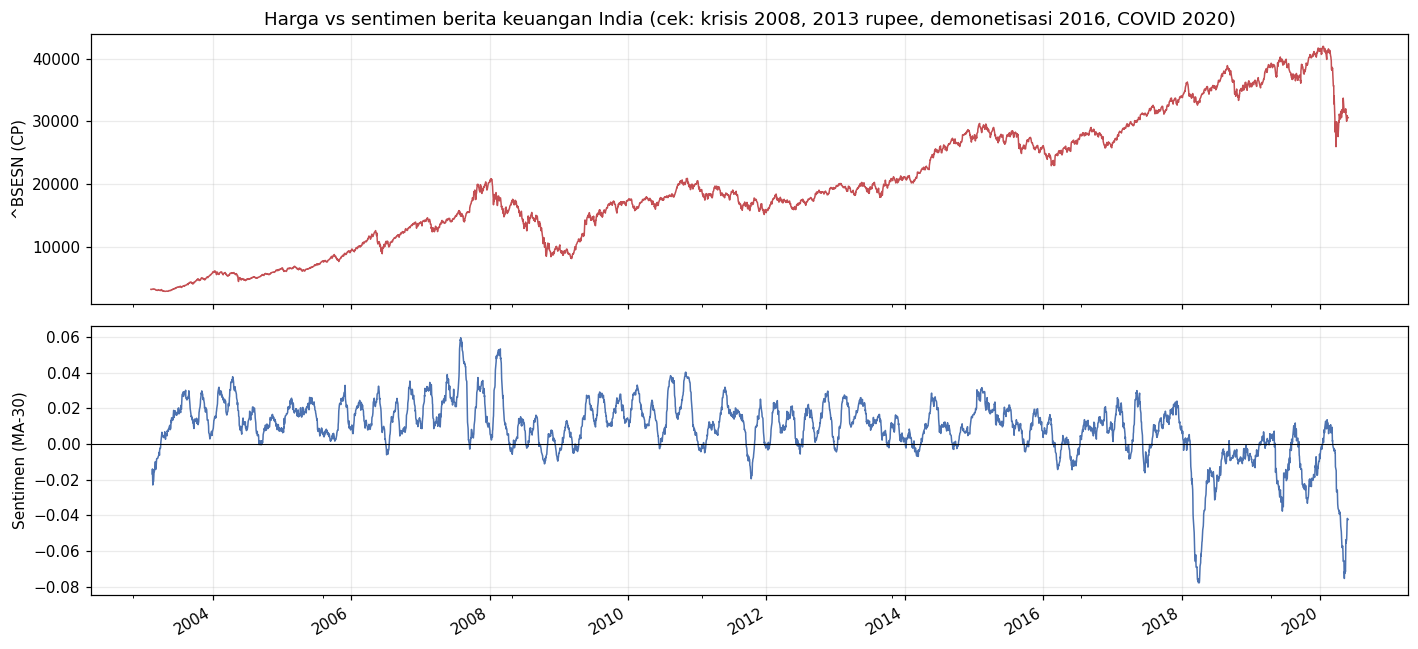

Korelasi fitur vs return BERIKUTNYA (kecil = wajar, pasar sulit diprediksi):
sent        0.012
sent_ma3    0.007
econ        0.032
fin         0.003
fear       -0.019
trend       0.016
vol         0.009
ret_1       0.051

Korelasi sentimen vs return HARI YANG SAMA (berita sering merangkum pergerakan hari itu): 0.015


In [6]:
fig, ax = plt.subplots(2, 1, figsize=(13, 6), sharex=True)
daily.set_index("Date").cp.plot(ax=ax[0], color="#C44E52", lw=1); ax[0].set_ylabel(f"{INDEX_TICKER} (CP)")
daily.set_index("Date").sent.rolling(30, min_periods=5).mean().plot(ax=ax[1], color="#4C72B0", lw=1)
ax[1].axhline(0, color="k", lw=.7); ax[1].set_ylabel("Sentimen (MA-30)"); ax[1].set_xlabel("")
ax[0].set_title("Harga vs sentimen berita keuangan India (cek: krisis 2008, 2013 rupee, demonetisasi 2016, COVID 2020)")
plt.tight_layout(); plt.savefig("figs/sentimen_vs_harga.png"); plt.show()

corr = daily[["sent","sent_ma3","econ","fin","fear","trend","vol","ret_1"]].corrwith(daily.ret_next).round(3)
print("Korelasi fitur vs return BERIKUTNYA (kecil = wajar, pasar sulit diprediksi):"); print(corr.to_string())
print("\nKorelasi sentimen vs return HARI YANG SAMA (berita sering merangkum pergerakan hari itu):",
      round(daily.sent.corr(daily.ret_1), 3))

## 4. Knowledge Base & Inference Engine

**Alur fakta → aturan → keputusan**
1. **Fakta numerik** (sentimen, tren harga, volatilitas, dll.) diubah menjadi **label linguistik** (fuzzifikasi sederhana): mis. `sentimen = very_neg`, `tren = oversold`.
2. **Forward chaining**: semua aturan `IF … THEN aksi (CF)` dievaluasi terhadap fakta.
3. **Certainty Factor (MYCIN)**: bila beberapa aturan mendukung aksi yang sama → `CF = CF₁ + CF₂ × (1 − CF₁)`.
4. **Conflict resolution**: aksi dengan CF tertinggi menang; BUY vs SELL harus unggul ≥ **0.15** dan CF ≥ **0.30**, jika tidak → **HOLD** (sinyal bertentangan = tunggu).

> **Catatan adaptasi:** sel di bawah mendefinisikan **KB awal** (16 aturan, CF, dan ambang fuzzifikasi hasil kalibrasi pada S&P 500). Pada data India, ambang sentimen dan bobot CF **dikalibrasi ulang hanya dari data latih** (bagian 6.0) lalu divalidasi; struktur & kondisi 16 aturan tetap. Angka seperti "data latih ±67% HOLD" pada kolom *Dasar* berasal dari kalibrasi S&P 500 dan tidak lagi berlaku apa adanya.

**Pembuatan aturan:** kombinasi (a) teori dari referensi, dan (b) statistik **data latih saja (≤2019)** – misalnya aturan “pasar tenang → HOLD” dan “sentimen sangat negatif + harga jatuh dalam → BUY (kontrarian)” terbukti lebih sering benar daripada peluang dasar di data latih, sedangkan aturan “ikuti momentum” justru **dibuang** karena data latih menunjukkan hasil lebih buruk dari acak.

In [7]:
# ---------- Fuzzifikasi: angka → label linguistik ----------
# Ambang yang bisa dikalibrasi ulang (nilai awal = KB awal dari S&P 500); ambang lain (tren, volatilitas, aspek) tidak diubah
TH_ORIG = {'sent': (-0.08, -0.03, 0.03, 0.08), 'fear': 0.25}
TH = dict(TH_ORIG)
def level(x, vneg=-0.08, neg=-0.03, pos=0.03, vpos=0.08):
    return 'very_neg' if x<=vneg else 'neg' if x<=neg else 'very_pos' if x>=vpos else 'pos' if x>=pos else 'neutral'
def asp_level(x, t=0.05):   return 'neg' if x<=-t else 'pos' if x>=t else 'none'
def trend_level(x):         return 'oversold' if x<=-0.06 else 'down' if x<=-0.02 else 'overextended' if x>=0.05 else 'up' if x>=0.02 else 'flat'
def delta_level(x, t=0.02): return 'improving' if x>=t else 'deteriorating' if x<=-t else 'stable'
def vol_level(x):           return 'high' if x>=0.018 else 'low' if x<=0.006 else 'normal'
def fear_level(x, t=0.25):  return 'high' if x>=t else 'none'

def fuzzify(f):
    return {'sent': level(f['sent_ma3'], *TH['sent']), 'delta': delta_level(f['sent_delta']), 'trend': trend_level(f['trend']),
            'vol': vol_level(f['vol']), 'fear': fear_level(f['fear'], TH['fear']),
            'econ': asp_level(f['econ'], 0.03), 'fin': asp_level(f['fin'], 0.05), 'mon': asp_level(f['a_monetary'], 0.05),
            'infl': asp_level(f['a_inflation'], 0.05), 'unemp': asp_level(f['a_unemployment'], 0.05),
            'manuf': asp_level(f['a_manufacturing'], 0.05),
            'volume': 'low' if f['n'] <= 1 else 'high' if f['n'] >= 15 else 'normal'}

# ---------- KNOWLEDGE BASE: (id, nama, kondisi, aksi, CF, dasar) ----------
RULES = [
 ('R01','Pasar tenang',              lambda F: F['vol']=='low',                                                          'HOLD',0.55,'Volatility clustering: pasar tenang → pergerakan kecil (data latih ±67% HOLD)'),
 ('R02','Euforia + jenuh beli',      lambda F: F['sent']=='very_pos' and F['trend']=='overextended',                     'SELL',0.30,'Risiko bubble saat sentimen ekstrem (Maghyereh & Abdoh, 2022)'),
 ('R03','Pesimis + tren turun',      lambda F: F['sent'] in('neg','very_neg') and F['delta']=='deteriorating' and F['trend']=='down','SELL',0.35,'Sentimen memburuk sejalan dengan tren turun'),
 ('R04','Kontrarian oversold',       lambda F: F['sent'] in('neg','very_neg') and F['trend']=='oversold',                'BUY', 0.60,'Sentimen bearish ekstrem + harga jatuh dalam → peluang rebound'),
 ('R05','Panik mereda',              lambda F: F['fear']=='high' and F['delta']=='improving',                            'BUY', 0.40,'Kata krisis/crash banyak namun sentimen mulai membaik'),
 ('R06','Volatilitas tinggi + turun',lambda F: F['vol']=='high' and F['trend'] in('down','oversold'),                    'BUY', 0.45,'Capitulation / mean reversion jangka pendek (data latih ±50% BUY)'),
 ('R07','Resesi ganda',              lambda F: F['econ']=='neg' and F['fin']=='neg',                                     'SELL',0.55,'Sentimen ekonomi & sektor keuangan sama-sama negatif (Barbaglia et al., 2022)'),
 ('R08','Pelonggaran moneter',       lambda F: F['mon']=='pos' and F['trend']!='overextended',                           'BUY', 0.40,'Kebijakan longgar mendorong aset berisiko (Maghyereh & Abdoh, 2022)'),
 ('R09','Inflasi + suku bunga naik', lambda F: F['infl']=='neg' and F['mon']=='neg',                                     'SELL',0.40,'Tekanan inflasi & pengetatan moneter'),
 ('R10','Ekonomi & manufaktur +',    lambda F: F['econ']=='pos' and F['manuf']=='pos',                                   'BUY', 0.45,'Sinyal ekspansi sektor riil (Barbaglia et al., 2022)'),
 ('R11','Tenaga kerja negatif',      lambda F: F['unemp']=='neg' and F['sent'] in('neg','very_neg','neutral'),           'SELL',0.55,'PHK/pengangguran naik → indikasi pelemahan ekonomi'),
 ('R12','Netral & datar',            lambda F: F['sent']=='neutral' and F['trend']=='flat',                              'HOLD',0.45,'Tidak ada sinyal kuat'),
 ('R13','Sentimen sangat negatif',   lambda F: F['sent']=='very_neg',                                                    'BUY', 0.35,'Kontrarian: pesimisme ekstrem sering diikuti pemulihan'),
 ('R14','Tren naik stabil',          lambda F: F['trend']=='up' and F['vol']!='high',                                    'HOLD',0.50,'Tren naik berjalan pelan (data latih ±67% HOLD)'),
 ('R15','Optimis + tren naik',       lambda F: F['sent'] in('pos','very_pos') and F['trend'] in('up','overextended'),    'HOLD',0.45,'Tidak ada keunggulan mengejar momentum (data latih ±64% HOLD)'),
 ('R16','Berita sedikit',            lambda F: F['volume']=='low' and F['sent']=='neutral',                              'HOLD',0.25,'Informasi tidak memadai'),
]
MIN_CF, MIN_MARGIN = 0.30, 0.15

# ---- KB awal disimpan; KB aktif bisa diganti dengan apply_kb() (dipakai untuk kalibrasi & perbandingan) ----
RULES_ORIG = tuple(RULES)
ORIG_KB = {'TH': TH_ORIG, 'RULES': RULES_ORIG}
def apply_kb(cfg):
    global TH, RULES
    TH, RULES = dict(cfg['TH']), list(cfg['RULES'])

def infer(F):
    """Forward chaining + kombinasi Certainty Factor. Return (keputusan, cf_per_aksi, aturan_aktif)."""
    cf, fired = {'BUY':0.0, 'SELL':0.0, 'HOLD':0.0}, []
    for rid, name, cond, act, c, src in RULES:
        if cond(F):
            cf[act] = cf[act] + c*(1-cf[act]); fired.append((rid, name, act, c))
    best = max(cf, key=cf.get)
    if best in ('BUY','SELL'):
        other = 'SELL' if best == 'BUY' else 'BUY'
        if cf[best] < MIN_CF or cf[best]-cf[other] < MIN_MARGIN: best = 'HOLD'      # konflik / lemah → tunggu
    elif cf['HOLD'] < MIN_CF: best = 'HOLD'
    return best, cf, fired

kb_table = pd.DataFrame([{"ID": r[0], "Nama": r[1], "Aksi": r[3], "CF": r[4], "Dasar / sumber": r[5]} for r in RULES])
kb_table

,ID,Nama,Aksi,CF,Dasar / sumber
0,R01,Pasar tenang,HOLD,0.55,Volatility clustering: pasar tenang → pergerakan kecil (data latih ±67% HOLD)
1,R02,Euforia + jenuh beli,SELL,0.30,"Risiko bubble saat sentimen ekstrem (Maghyereh & Abdoh, 2022)"
2,R03,Pesimis + tren turun,SELL,0.35,Sentimen memburuk sejalan dengan tren turun
3,R04,Kontrarian oversold,BUY,0.60,Sentimen bearish ekstrem + harga jatuh dalam → peluang rebound
4,R05,Panik mereda,BUY,0.40,Kata krisis/crash banyak namun sentimen mulai membaik
5,R06,Volatilitas tinggi + turun,BUY,0.45,Capitulation / mean reversion jangka pendek (data latih ±50% BUY)
6,R07,Resesi ganda,SELL,0.55,"Sentimen ekonomi & sektor keuangan sama-sama negatif (Barbaglia et al., 2022)"
7,R08,Pelonggaran moneter,BUY,0.40,"Kebijakan longgar mendorong aset berisiko (Maghyereh & Abdoh, 2022)"
8,R09,Inflasi + suku bunga naik,SELL,0.40,Tekanan inflasi & pengetatan moneter
9,R10,Ekonomi & manufaktur +,BUY,0.45,"Sinyal ekspansi sektor riil (Barbaglia et al., 2022)"


### 4.1 Knowledge base dalam bentuk IF–THEN (untuk laporan)

In [8]:
IF_TEXT = {
 'R01':"IF volatilitas = rendah",
 'R02':"IF sentimen = sangat positif AND harga = jenuh beli (>5% di atas MA20)",
 'R03':"IF sentimen ∈ {negatif, sangat negatif} AND sentimen memburuk AND tren = turun",
 'R04':"IF sentimen ∈ {negatif, sangat negatif} AND harga = oversold (<-6% dari MA20)",
 'R05':"IF proporsi headline 'panik' tinggi AND sentimen membaik",
 'R06':"IF volatilitas = tinggi AND tren ∈ {turun, oversold}",
 'R07':"IF sentimen ekonomi = negatif AND sentimen sektor keuangan = negatif",
 'R08':"IF sentimen kebijakan moneter = positif AND harga tidak jenuh beli",
 'R09':"IF sentimen inflasi = negatif AND sentimen moneter = negatif",
 'R10':"IF sentimen ekonomi = positif AND sentimen manufaktur = positif",
 'R11':"IF sentimen tenaga kerja = negatif AND sentimen umum ∈ {negatif, sangat negatif, netral}",
 'R12':"IF sentimen = netral AND tren = datar",
 'R13':"IF sentimen = sangat negatif",
 'R14':"IF tren = naik AND volatilitas ≠ tinggi",
 'R15':"IF sentimen ∈ {positif, sangat positif} AND tren ∈ {naik, jenuh beli}",
 'R16':"IF jumlah berita ≤ 1 AND sentimen = netral",
}
for r in RULES:
    print(f"{r[0]}  {IF_TEXT[r[0]]}\n     THEN {r[3]}  (CF = {r[4]})   # {r[1]}")

R01  IF volatilitas = rendah
     THEN HOLD  (CF = 0.55)   # Pasar tenang
R02  IF sentimen = sangat positif AND harga = jenuh beli (>5% di atas MA20)
     THEN SELL  (CF = 0.3)   # Euforia + jenuh beli
R03  IF sentimen ∈ {negatif, sangat negatif} AND sentimen memburuk AND tren = turun
     THEN SELL  (CF = 0.35)   # Pesimis + tren turun
R04  IF sentimen ∈ {negatif, sangat negatif} AND harga = oversold (<-6% dari MA20)
     THEN BUY  (CF = 0.6)   # Kontrarian oversold
R05  IF proporsi headline 'panik' tinggi AND sentimen membaik
     THEN BUY  (CF = 0.4)   # Panik mereda
R06  IF volatilitas = tinggi AND tren ∈ {turun, oversold}
     THEN BUY  (CF = 0.45)   # Volatilitas tinggi + turun
R07  IF sentimen ekonomi = negatif AND sentimen sektor keuangan = negatif
     THEN SELL  (CF = 0.55)   # Resesi ganda
R08  IF sentimen kebijakan moneter = positif AND harga tidak jenuh beli
     THEN BUY  (CF = 0.4)   # Pelonggaran moneter
R09  IF sentimen inflasi = negatif AND sentimen moneter = negatif


## 5. Diagram Sistem (untuk laporan)
### 5.1 Arsitektur sistem

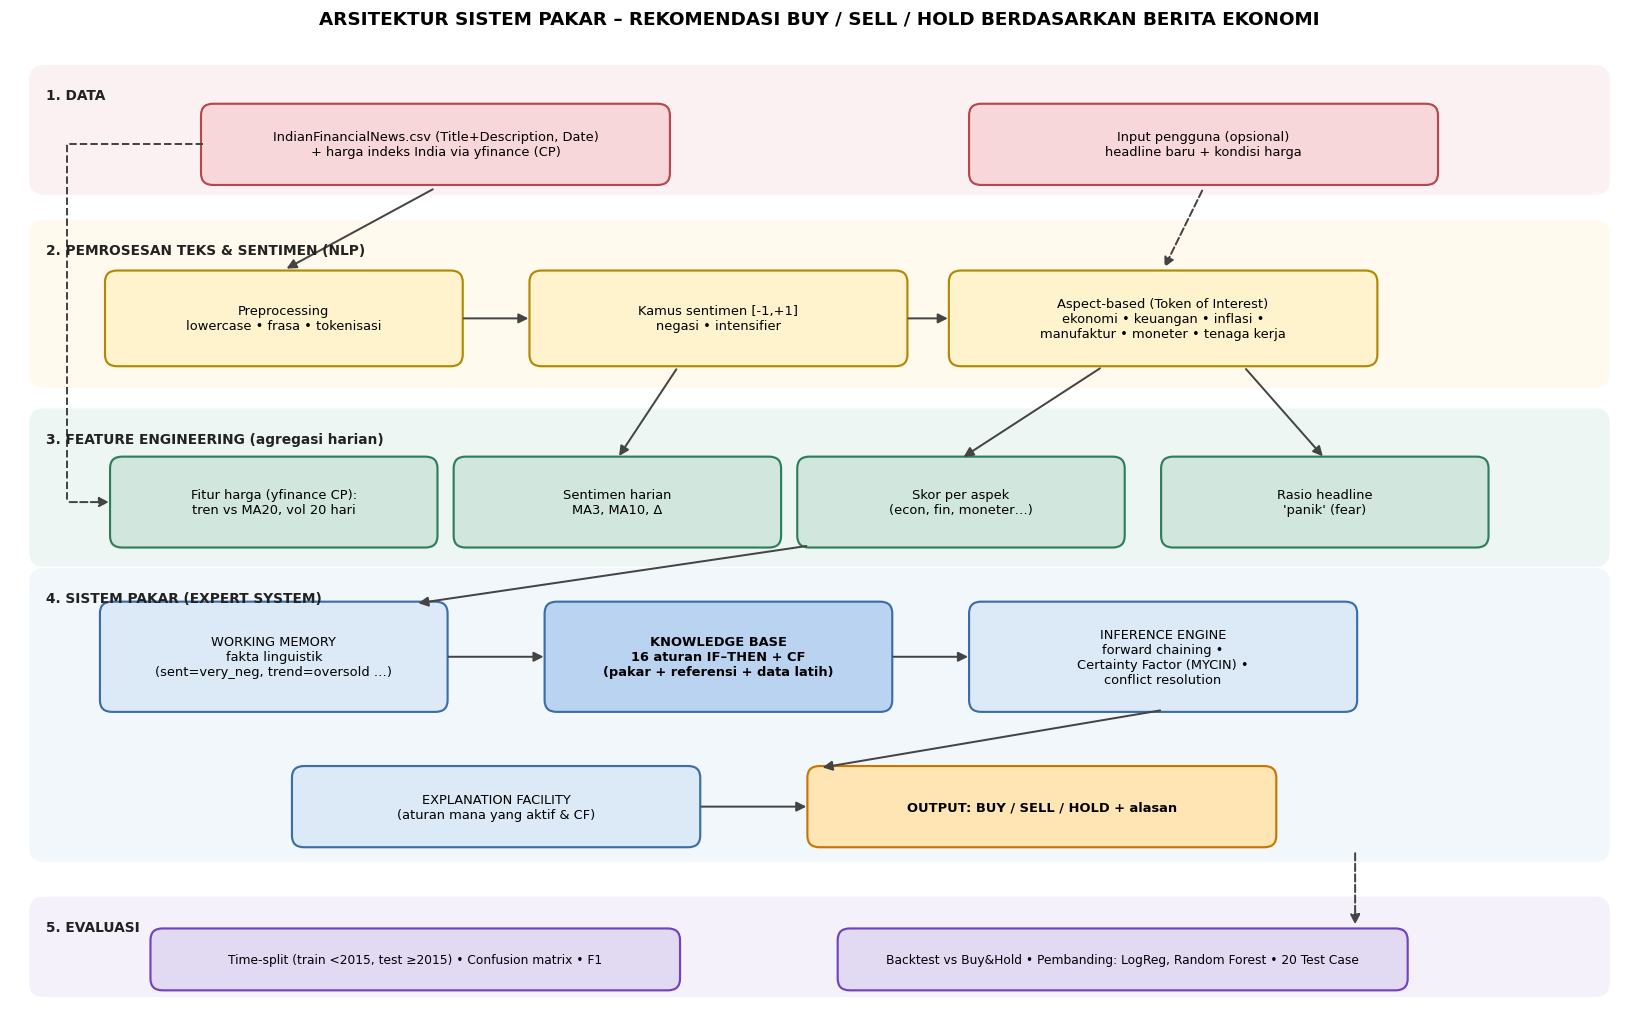

In [9]:
def _box(ax, x, y, w, h, text, fc="#DCE9F7", ec="#3B6EA5", fs=8.5, bold=False):
    ax.add_patch(FancyBboxPatch((x-w/2, y-h/2), w, h, boxstyle="round,pad=0.02,rounding_size=0.12", fc=fc, ec=ec, lw=1.4))
    ax.text(x, y, text, ha="center", va="center", fontsize=fs, fontweight="bold" if bold else "normal", wrap=True)
def _arrow(ax, x1, y1, x2, y2, label=None, color="#444", ls="-"):
    ax.add_patch(FancyArrowPatch((x1, y1), (x2, y2), arrowstyle="-|>", mutation_scale=13, color=color, lw=1.3, linestyle=ls))
    if label: ax.text((x1+x2)/2+0.08, (y1+y2)/2+0.08, label, fontsize=8, color=color, ha="left")
def _layer(ax, y, h, title, color):
    ax.add_patch(FancyBboxPatch((0.2, y-h/2), 15.6, h, boxstyle="round,pad=0.02,rounding_size=0.15", fc=color, ec="none", alpha=.35))
    ax.text(0.35, y+h/2-0.22, title, fontsize=9, fontweight="bold", color="#222", va="top")

def draw_architecture(path="figs/arsitektur_sistem.png"):
    fig, ax = plt.subplots(figsize=(15, 9.3)); ax.set_xlim(0, 16); ax.set_ylim(0, 10); ax.axis("off"); ax.grid(False)
    ax.set_title("ARSITEKTUR SISTEM PAKAR – REKOMENDASI BUY / SELL / HOLD BERDASARKAN BERITA EKONOMI", fontsize=12, fontweight="bold")
    _layer(ax, 9.0, 1.3, "1. DATA", "#F8D7DA");            _box(ax, 4.2, 8.85, 4.6, .8, "IndianFinancialNews.csv (Title+Description, Date)\n+ harga indeks India via yfinance (CP)", "#F8D7DA", "#B5474E")
    _box(ax, 11.8, 8.85, 4.6, .8, "Input pengguna (opsional)\nheadline baru + kondisi harga", "#F8D7DA", "#B5474E")
    _layer(ax, 7.2, 1.7, "2. PEMROSESAN TEKS & SENTIMEN (NLP)", "#FFF3CD")
    _box(ax, 2.7, 7.05, 3.5, .95, "Preprocessing\nlowercase • frasa • tokenisasi", "#FFF3CD", "#B08900")
    _box(ax, 7.0, 7.05, 3.7, .95, "Kamus sentimen [-1,+1]\nnegasi • intensifier", "#FFF3CD", "#B08900")
    _box(ax, 11.4, 7.05, 4.2, .95, "Aspect-based (Token of Interest)\nekonomi • keuangan • inflasi •\nmanufaktur • moneter • tenaga kerja", "#FFF3CD", "#B08900")
    _layer(ax, 5.3, 1.6, "3. FEATURE ENGINEERING (agregasi harian)", "#D1E7DD")
    for x, t in [(2.6, "Fitur harga (yfinance CP):\ntren vs MA20, vol 20 hari"), (6.0, "Sentimen harian\nMA3, MA10, Δ"), (9.4, "Skor per aspek\n(econ, fin, moneter…)"), (13.0, "Rasio headline\n'panik' (fear)")]:
        _box(ax, x, 5.15, 3.2, .9, t, "#D1E7DD", "#2E7D5B")
    _layer(ax, 2.95, 3.0, "4. SISTEM PAKAR (EXPERT SYSTEM)", "#DCE9F7")
    _box(ax, 2.6, 3.55, 3.4, 1.1, "WORKING MEMORY\nfakta linguistik\n(sent=very_neg, trend=oversold …)", "#DCE9F7", "#3B6EA5", bold=False)
    _box(ax, 7.0, 3.55, 3.4, 1.1, "KNOWLEDGE BASE\n16 aturan IF–THEN + CF\n(pakar + referensi + data latih)", "#B9D3F0", "#3B6EA5", bold=True)
    _box(ax, 11.4, 3.55, 3.8, 1.1, "INFERENCE ENGINE\nforward chaining •\nCertainty Factor (MYCIN) •\nconflict resolution", "#DCE9F7", "#3B6EA5")
    _box(ax, 4.8, 2.0, 4.0, .8, "EXPLANATION FACILITY\n(aturan mana yang aktif & CF)", "#DCE9F7", "#3B6EA5")
    _box(ax, 10.2, 2.0, 4.6, .8, "OUTPUT: BUY / SELL / HOLD + alasan", "#FFE5B4", "#C77700", bold=True)
    _layer(ax, 0.55, 1.0, "5. EVALUASI", "#E2D9F3")
    _box(ax, 4.0, 0.42, 5.2, .6, "Time-split (train <2015, test ≥2015) • Confusion matrix • F1", "#E2D9F3", "#6F42C1", fs=8)
    _box(ax, 11.0, 0.42, 5.6, .6, "Backtest vs Buy&Hold • Pembanding: LogReg, Random Forest • 20 Test Case", "#E2D9F3", "#6F42C1", fs=8)
    _arrow(ax, 4.2, 8.4, 2.7, 7.55)                       # CSV → preprocessing
    _arrow(ax, 11.8, 8.4, 11.4, 7.55, ls="--")             # input pengguna → NLP
    ax.plot([1.9, 0.55, 0.55], [8.85, 8.85, 5.15], color="#444", lw=1.3, ls="--"); _arrow(ax, 0.55, 5.15, 1.0, 5.15, color="#444", ls="--")  # kolom CP
    _arrow(ax, 4.45, 7.05, 5.15, 7.05); _arrow(ax, 8.85, 7.05, 9.3, 7.05)
    _arrow(ax, 6.6, 6.55, 6.0, 5.6); _arrow(ax, 10.8, 6.55, 9.4, 5.6); _arrow(ax, 12.2, 6.55, 13.0, 5.6)
    _arrow(ax, 7.9, 4.7, 4.0, 4.1)                         # fitur → working memory
    _arrow(ax, 4.3, 3.55, 5.3, 3.55); _arrow(ax, 8.7, 3.55, 9.5, 3.55)
    _arrow(ax, 11.4, 3.0, 8.0, 2.4); _arrow(ax, 6.8, 2.0, 7.9, 2.0)
    _arrow(ax, 13.3, 1.55, 13.3, 0.75, ls="--")
    plt.tight_layout(); plt.savefig(path, bbox_inches="tight"); plt.show()

draw_architecture()

### 5.2 Flowchart program

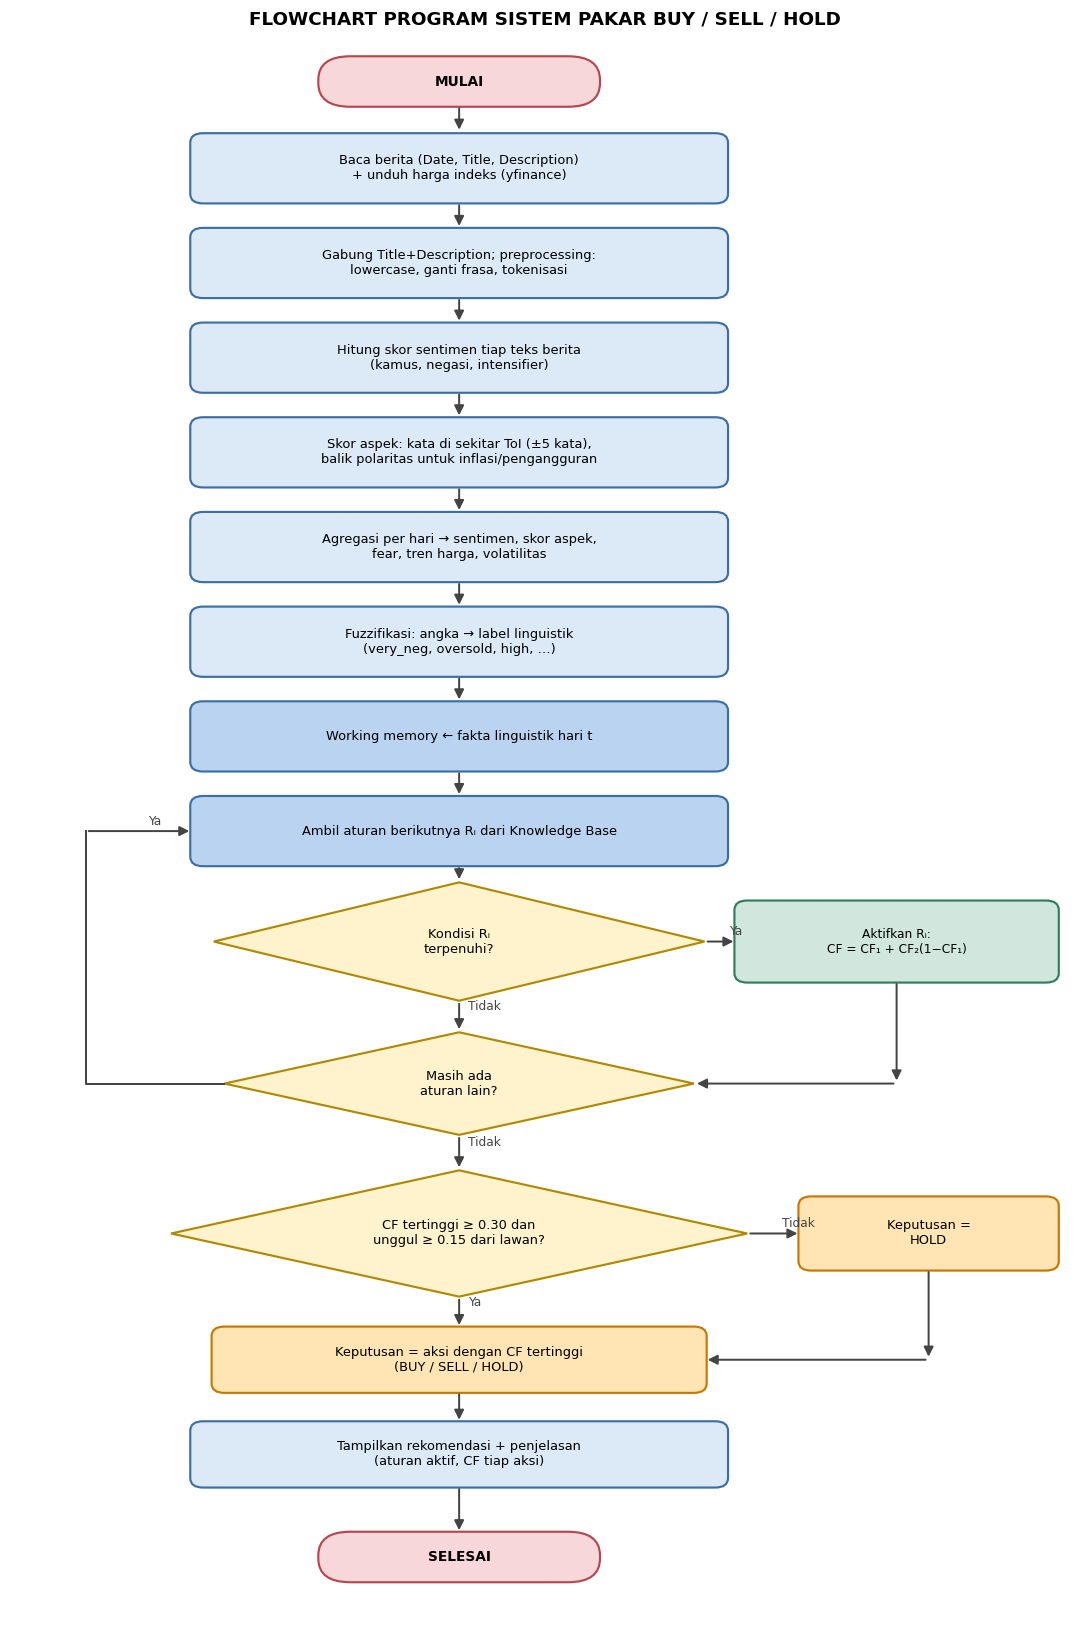

In [10]:
def _diamond(ax, x, y, w, h, text, fc="#FFF3CD", ec="#B08900", fs=8.5):
    ax.add_patch(Polygon([(x, y+h/2), (x+w/2, y), (x, y-h/2), (x-w/2, y)], closed=True, fc=fc, ec=ec, lw=1.4))
    ax.text(x, y, text, ha="center", va="center", fontsize=fs)
def _term(ax, x, y, text, w=2.6, h=.6):
    ax.add_patch(FancyBboxPatch((x-w/2, y-h/2), w, h, boxstyle="round,pad=0.02,rounding_size=0.3", fc="#F8D7DA", ec="#B5474E", lw=1.4))
    ax.text(x, y, text, ha="center", va="center", fontsize=9, fontweight="bold")

def draw_flowchart(path="figs/flowchart.png"):
    fig, ax = plt.subplots(figsize=(10, 15)); ax.set_xlim(0, 10); ax.set_ylim(0, 20.2); ax.axis("off"); ax.grid(False)
    ax.set_title("FLOWCHART PROGRAM SISTEM PAKAR BUY / SELL / HOLD", fontsize=12, fontweight="bold")
    X = 4.2
    _term(ax, X, 19.6, "MULAI")
    steps = [(18.5, "Baca berita (Date, Title, Description)\n+ unduh harga indeks (yfinance)"),
             (17.3, "Gabung Title+Description; preprocessing:\nlowercase, ganti frasa, tokenisasi"),
             (16.1, "Hitung skor sentimen tiap teks berita\n(kamus, negasi, intensifier)"),
             (14.9, "Skor aspek: kata di sekitar ToI (±5 kata),\nbalik polaritas untuk inflasi/pengangguran"),
             (13.7, "Agregasi per hari → sentimen, skor aspek,\nfear, tren harga, volatilitas"),
             (12.5, "Fuzzifikasi: angka → label linguistik\n(very_neg, oversold, high, …)")]
    for y, t in steps: _box(ax, X, y, 5.0, .85, t, fs=8.5)
    _arrow(ax, X, 19.3, X, 18.95)
    ys = [18.5, 17.3, 16.1, 14.9, 13.7, 12.5]
    for a, b in zip(ys[:-1], ys[1:]): _arrow(ax, X, a-.43, X, b+.43)
    _box(ax, X, 11.3, 5.0, .85, "Working memory ← fakta linguistik hari t", "#B9D3F0", "#3B6EA5", fs=8.5); _arrow(ax, X, 12.07, X, 11.73)
    _box(ax, X, 10.1, 5.0, .85, "Ambil aturan berikutnya Rᵢ dari Knowledge Base", "#B9D3F0", "#3B6EA5", fs=8.5); _arrow(ax, X, 10.87, X, 10.53)
    _diamond(ax, X, 8.7, 4.6, 1.5, "Kondisi Rᵢ\nterpenuhi?"); _arrow(ax, X, 9.67, X, 9.45)
    _box(ax, 8.3, 8.7, 3.0, 1.0, "Aktifkan Rᵢ:\nCF = CF₁ + CF₂(1−CF₁)", "#D1E7DD", "#2E7D5B", fs=8); _arrow(ax, X+2.3, 8.7, 6.8, 8.7, "Ya")
    _diamond(ax, X, 6.9, 4.4, 1.3, "Masih ada\naturan lain?"); _arrow(ax, X, 7.95, X, 7.55, "Tidak")
    _arrow(ax, 8.3, 8.2, 8.3, 6.9); _arrow(ax, 8.3, 6.9, X+2.2, 6.9)
    ax.plot([X-2.2, 0.7, 0.7], [6.9, 6.9, 10.1], color="#444", lw=1.3); _arrow(ax, 0.7, 10.1, X-2.5, 10.1, "Ya")
    _diamond(ax, X, 5.0, 5.4, 1.6, "CF tertinggi ≥ 0.30 dan\nunggul ≥ 0.15 dari lawan?"); _arrow(ax, X, 6.25, X, 5.8, "Tidak")
    _box(ax, X, 3.4, 4.6, .8, "Keputusan = aksi dengan CF tertinggi\n(BUY / SELL / HOLD)", "#FFE5B4", "#C77700", fs=8.5); _arrow(ax, X, 4.2, X, 3.8, "Ya")
    _box(ax, 8.6, 5.0, 2.4, .9, "Keputusan =\nHOLD", "#FFE5B4", "#C77700", fs=8.5); _arrow(ax, X+2.7, 5.0, 7.4, 5.0, "Tidak")
    _arrow(ax, 8.6, 4.55, 8.6, 3.4); _arrow(ax, 8.6, 3.4, X+2.3, 3.4)
    _box(ax, X, 2.2, 5.0, .8, "Tampilkan rekomendasi + penjelasan\n(aturan aktif, CF tiap aksi)", "#DCE9F7", "#3B6EA5", fs=8.5); _arrow(ax, X, 3.0, X, 2.6)
    _term(ax, X, 0.9, "SELESAI"); _arrow(ax, X, 1.8, X, 1.2)
    plt.tight_layout(); plt.savefig(path, bbox_inches="tight"); plt.show()

draw_flowchart()

## 6. Evaluasi pada Data Historis
**Skema:** pembagian **berdasarkan waktu** (bukan acak, agar tidak ada kebocoran masa depan):
- **Train** : sebelum `SPLIT_DATE` (**< 01-01-2015**), dibagi lagi menjadi *fit* (2003–2011, untuk kalibrasi) dan *validasi* (2012–2014, untuk memutuskan apakah kalibrasi dipakai)
- **Test**  : sejak `SPLIT_DATE` (**≥ 01-01-2015 s.d. Mei 2020**, ±1.300 hari) – **hanya disentuh satu kali di akhir**, tidak dipakai untuk menyetel apa pun

Metrik (mengikuti survei referensi ke-3): accuracy, precision, recall, F1, confusion matrix.

### 6.0 Kalibrasi ulang KB untuk data India (hanya data latih)
KB awal dikalibrasi pada S&P 500, sehingga di data India (a) skala sentimen bergeser (±77% hari "netral", hampir tidak ada hari `very_neg`) dan (b) sebagian aturan tidak punya keunggulan. Kalibrasi **tidak mengubah metode** (forward chaining + CF MYCIN, 16 aturan, `MIN_CF`, `MIN_MARGIN`); hanya parameter:

| Parameter | Cara kalibrasi (pada data *fit* saja) |
|---|---|
| Ambang sentimen `very_neg / neg / pos / very_pos` | persentil ke-5 / 20 / 80 / 95 dari `sent_ma3` |
| Ambang `fear` tinggi | persentil ke-95 dari `fear` |
| CF tiap aturan | uji lift: presisi aturan vs peluang dasar aksinya, `z = (presisi − dasar)/√(dasar(1−dasar)/n)`. Hanya aturan dengan **n ≥ 30 hari aktif** yang disesuaikan: `z ≥ 2` → CF ×1,2 (maks 0,9); `z ≤ −1` → CF ×0,5; `z ≤ −2` → dinonaktifkan. Aturan dengan n < 30 **dipertahankan** (CF pakar), karena sampelnya terlalu kecil untuk dijadikan bukti |

**Validasi:** KB terkalibrasi (dari *fit*) dibandingkan dengan KB awal pada data *validasi*. Bila macro-F1 tidak lebih buruk, kalibrasi diulang pada seluruh data latih dan dipakai; bila lebih buruk, KB awal dipertahankan. Data uji tidak terlibat.

In [11]:
# ---------- 6.0a Pembagian data + fungsi kalibrasi ----------
train = data[data.Date <  SPLIT_DATE].copy()
test  = data[data.Date >= SPLIT_DATE].copy()
fit   = train[train.Date <  VALID_START].copy()      # kalibrasi
valid = train[train.Date >= VALID_START].copy()      # validasi (memilih kalibrasi vs KB awal)
print(f"Train {len(train)} hari ({train.Date.min().date()} → {train.Date.max().date()}) = fit {len(fit)} + validasi {len(valid)}")
print(f"Test  {len(test)} hari ({test.Date.min().date()} → {test.Date.max().date()})")
LABELS = ["BUY", "HOLD", "SELL"]

def _with_kb(cfg, fn):
    """Jalankan fn() dengan KB sementara = cfg, lalu kembalikan KB aktif semula."""
    old = {'TH': TH, 'RULES': RULES}; apply_kb(cfg)
    try: return fn()
    finally: apply_kb(old)

def predict_with(cfg, d):
    return _with_kb(cfg, lambda: [infer(fuzzify(r))[0] for _, r in d.iterrows()])

def kb_metrics(d, pred):
    pred = pd.Series(pred, index=d.index)
    _, _, f, _ = precision_recall_fscore_support(d.label, pred, labels=LABELS, zero_division=0)
    out = {"acc": accuracy_score(d.label, pred), "macroF1": f.mean()}
    for a in ["BUY", "SELL"]:
        m = pred == a; out["n_"+a] = int(m.sum()); out["prec_"+a] = (d.label[m] == a).mean() if m.sum() else np.nan
    return out

def calibrate_thresholds(d):
    q = d.sent_ma3.quantile([.05, .20, .80, .95]).values
    fr = float(d.fear.quantile(.95))
    return {'sent': tuple(float(x) for x in q), 'fear': fr if fr >= 0.05 else TH_ORIG['fear']}

N_MIN, Z_UP, Z_DOWN, Z_OFF = 30, 2.0, -1.0, -2.0
def calibrate_rules(d, th):
    """Sesuaikan CF tiap aturan dari bukti pada data d (struktur & kondisi aturan tidak diubah)."""
    fired = _with_kb({'TH': th, 'RULES': RULES_ORIG}, lambda: [set(f[0] for f in infer(fuzzify(r))[2]) for _, r in d.iterrows()])
    base = d.label.value_counts(normalize=True); lab = d.label.values
    new_rules, rows = [], []
    for rid, name, cond, act, cf, src_ in RULES_ORIG:
        m = np.array([rid in s for s in fired]); n = int(m.sum()); b = float(base.get(act, 0.0))
        prec = float((lab[m] == act).mean()) if n else np.nan
        z = (prec - b) / np.sqrt(b*(1-b)/n) if n and 0 < b < 1 else np.nan
        if   n >= N_MIN and z <= Z_OFF:  cf2, st = 0.0, "dinonaktifkan"
        elif n >= N_MIN and z <= Z_DOWN: cf2, st = round(cf*0.5, 3), "dilemahkan"
        elif n >= N_MIN and z >= Z_UP:   cf2, st = round(min(0.9, cf*1.2), 3), "diperkuat"
        elif n >= N_MIN:                 cf2, st = cf, "dipertahankan"
        else:                            cf2, st = cf, "data kurang → CF pakar"
        if cf2 > 0: new_rules.append((rid, name, cond, act, cf2, src_))
        rows.append({"ID": rid, "Aturan": name, "Aksi": act, "n aktif": n, "Presisi": prec, "Peluang dasar": b, "z": z, "CF awal": cf, "CF baru": cf2, "Status": st})
    return new_rules, pd.DataFrame(rows)

# ---- kalibrasi pada data FIT, uji di VALIDASI ----
th_fit = calibrate_thresholds(fit)
rules_fit, tbl_fit = calibrate_rules(fit, th_fit)
CAL_FIT = {'TH': th_fit, 'RULES': rules_fit}
cmp_val = pd.DataFrame({"KB awal (S&P, tanpa kalibrasi)": kb_metrics(valid, predict_with(ORIG_KB, valid)),
                        "KB terkalibrasi (dari fit)":      kb_metrics(valid, predict_with(CAL_FIT, valid))}).T
print("Perbandingan pada data VALIDASI (2012–2014):"); display(cmp_val.round(3))

Train 2927 hari (2003-02-10 → 2014-12-31) = fit 2197 + validasi 730
Test  1311 hari (2015-01-02 → 2020-05-26)
Perbandingan pada data VALIDASI (2012–2014):


,acc,macroF1,n_BUY,prec_BUY,n_SELL,prec_SELL
"KB awal (S&P, tanpa kalibrasi)",0.458,0.246,29.0,0.345,26.0,0.115
KB terkalibrasi (dari fit),0.464,0.285,74.0,0.338,23.0,0.217


In [12]:
# ---------- 6.0b Keputusan, kalibrasi akhir, KB final ----------
adopt = cmp_val.loc["KB terkalibrasi (dari fit)", "macroF1"] >= cmp_val.loc["KB awal (S&P, tanpa kalibrasi)", "macroF1"]
if adopt:
    th_final = calibrate_thresholds(train)                          # kalibrasi ulang pada SELURUH data latih
    rules_final, rule_calibration = calibrate_rules(train, th_final)
    FINAL_KB = {'TH': th_final, 'RULES': rules_final}
else:
    FINAL_KB = ORIG_KB; rule_calibration = tbl_fit.assign(Status="(tidak dipakai: kalibrasi ditolak validasi)")
apply_kb(FINAL_KB)
print("KEPUTUSAN:", "kalibrasi DIPAKAI (macro-F1 validasi tidak lebih buruk dari KB awal) → dikalibrasi ulang pada seluruh data latih" if adopt
      else "kalibrasi DITOLAK (macro-F1 validasi lebih buruk) → KB awal dipertahankan")
print("\nAmbang sentimen (very_neg, neg, pos, very_pos):")
print("  awal :", TH_ORIG['sent'], "| fear:", TH_ORIG['fear'])
print("  final:", tuple(round(x, 4) for x in FINAL_KB['TH']['sent']), "| fear:", round(FINAL_KB['TH']['fear'], 3))
print("\nSebaran label linguistik sentimen (final) – train vs test:")
for nm, d in [("train", train), ("test", test)]:
    print(f"  {nm:5s}:", pd.Series([fuzzify(r)['sent'] for _, r in d.iterrows()]).value_counts(normalize=True).round(3).to_dict())
display(rule_calibration.round(3))
kb_final = pd.DataFrame([{"ID": r[0], "Nama": r[1], "Aksi": r[3], "CF": r[4]} for r in RULES])

KEPUTUSAN: kalibrasi DIPAKAI (macro-F1 validasi tidak lebih buruk dari KB awal) → dikalibrasi ulang pada seluruh data latih

Ambang sentimen (very_neg, neg, pos, very_pos):
  awal : (-0.08, -0.03, 0.03, 0.08) | fear: 0.25
  final: (-0.0224, -0.0037, 0.0308, 0.0554) | fear: 0.143

Sebaran label linguistik sentimen (final) – train vs test:
  train: {'neutral': 0.6, 'pos': 0.15, 'neg': 0.15, 'very_neg': 0.05, 'very_pos': 0.05}
  test : {'neutral': 0.43, 'neg': 0.233, 'very_neg': 0.207, 'pos': 0.105, 'very_pos': 0.025}


,ID,Aturan,Aksi,n aktif,Presisi,Peluang dasar,z,CF awal,CF baru,Status
0,R01,Pasar tenang,HOLD,106,0.491,0.352,2.998,0.55,0.660,diperkuat
1,R02,Euforia + jenuh beli,SELL,14,0.357,0.288,0.568,0.30,0.300,data kurang → CF pakar
2,R03,Pesimis + tren turun,SELL,41,0.537,0.288,3.509,0.35,0.420,diperkuat
3,R04,Kontrarian oversold,BUY,47,0.532,0.360,2.454,0.60,0.720,diperkuat
4,R05,Panik mereda,BUY,9,0.000,0.360,-2.250,0.40,0.400,data kurang → CF pakar
5,R06,Volatilitas tinggi + turun,BUY,205,0.439,0.360,2.354,0.45,0.540,diperkuat
6,R07,Resesi ganda,SELL,42,0.286,0.288,-0.038,0.55,0.550,dipertahankan
7,R08,Pelonggaran moneter,BUY,345,0.391,0.360,1.208,0.40,0.400,dipertahankan
8,R09,Inflasi + suku bunga naik,SELL,34,0.324,0.288,0.453,0.40,0.400,dipertahankan
9,R10,Ekonomi & manufaktur +,BUY,55,0.273,0.360,-1.350,0.45,0.225,dilemahkan


[TRAIN]  n=2927  accuracy=0.374  macro-F1=0.264   | baseline 'selalu BUY' (mayoritas latih): 0.360 | baseline terkuat 'selalu BUY': 0.360
[TEST]  n=1311  accuracy=0.465  macro-F1=0.296   | baseline 'selalu BUY' (mayoritas latih): 0.276 | baseline terkuat 'selalu HOLD': 0.490

               precision    recall  f1-score   support

         BUY      0.306     0.188     0.233       362
        HOLD      0.509     0.837     0.633       643
        SELL      0.125     0.013     0.024       306

    accuracy                          0.465      1311
   macro avg      0.313     0.346     0.296      1311
weighted avg      0.363     0.465     0.380      1311



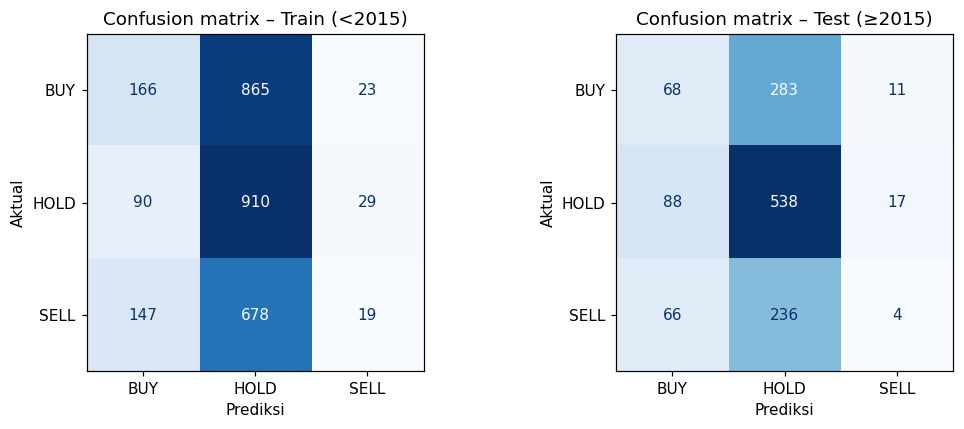

In [13]:
def run_es(x):
    out = [infer(fuzzify(r)) for _, r in x.iterrows()]
    return [o[0] for o in out], [o[1] for o in out], [o[2] for o in out]

# train/test sudah dibuat di 6.0a; KB aktif = KB final (hasil 6.0b)
train["pred"], _, _         = run_es(train)
test["pred"], test_cf, test_fired = run_es(test)
LABELS = ["BUY", "HOLD", "SELL"]
maj = train.label.mode()[0]

def report(x, name):
    acc = accuracy_score(x.label, x.pred)
    p, r, f, _ = precision_recall_fscore_support(x.label, x.pred, labels=LABELS, zero_division=0)
    print(f"[{name}]  n={len(x)}  accuracy={acc:.3f}  macro-F1={f.mean():.3f}   | baseline 'selalu {maj}' (mayoritas latih): {(x.label==maj).mean():.3f} | baseline terkuat 'selalu {x.label.mode()[0]}': {x.label.value_counts(normalize=True).max():.3f}")
    return acc

report(train, "TRAIN"); report(test, "TEST")
print("\n", classification_report(test.label, test.pred, labels=LABELS, digits=3, zero_division=0))

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
for a, x, nm in zip(ax, [train, test], [f"Train (<{SPLIT_DATE[:4]})", f"Test (≥{SPLIT_DATE[:4]})"]):
    ConfusionMatrixDisplay(confusion_matrix(x.label, x.pred, labels=LABELS), display_labels=LABELS).plot(ax=a, colorbar=False, cmap="Blues")
    a.set_title(f"Confusion matrix – {nm}"); a.grid(False); a.set_xlabel("Prediksi"); a.set_ylabel("Aktual")
plt.tight_layout(); plt.savefig("figs/confusion.png"); plt.show()

### 6.1 Pembanding: model Machine Learning pada fitur yang sama
Untuk melihat apakah sistem pakar masuk akal dibanding model *black box* (seperti pendekatan ML pada survei referensi ke-3).

,Model,Accuracy,Macro-F1
0,Baseline: selalu BUY (mayoritas data latih),0.276,0.144
1,Baseline: selalu HOLD (mayoritas data uji),0.490,0.219
2,"Sistem Pakar (KB final, rule-based CF)",0.465,0.296
3,Sistem Pakar – KB awal (tanpa kalibrasi),0.485,0.287
4,Logistic Regression,0.490,0.374
5,Random Forest,0.489,0.346


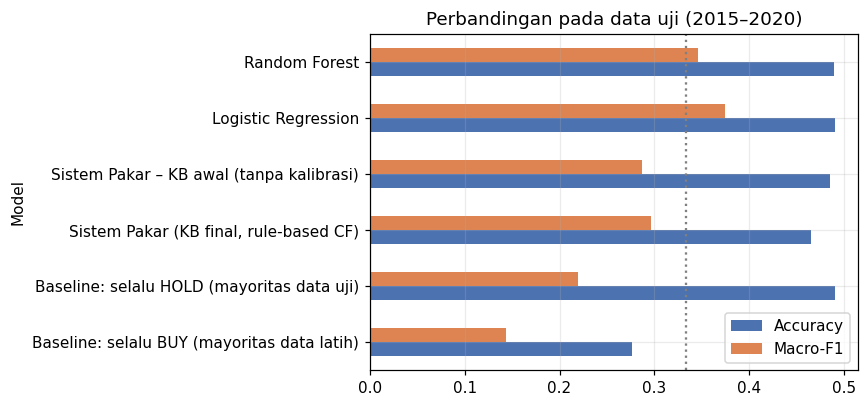

In [14]:
FEATS = ["sent_ma3","sent_delta","econ","fin","fear","trend","vol","n","a_market","a_monetary","a_inflation","a_unemployment","a_manufacturing"]
Xtr, Xte = train[FEATS], test[FEATS]

models = {
  "Logistic Regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
  "Random Forest":       RandomForestClassifier(n_estimators=300, min_samples_leaf=15, random_state=42, n_jobs=-1),
}
rows = [{"Model":"Baseline: selalu "+maj+" (mayoritas data latih)", "Accuracy":(test.label==maj).mean(), "Macro-F1":precision_recall_fscore_support(test.label,[maj]*len(test),labels=LABELS,zero_division=0)[2].mean()},
        {"Model":"Sistem Pakar (KB final, rule-based CF)", "Accuracy":accuracy_score(test.label,test.pred), "Macro-F1":precision_recall_fscore_support(test.label,test.pred,labels=LABELS,zero_division=0)[2].mean()}]
maj_te = test.label.mode()[0]       # pembanding saja: konstanta terbaik pada data uji
rows.insert(1, {"Model": "Baseline: selalu "+maj_te+" (mayoritas data uji)", "Accuracy": (test.label==maj_te).mean(),
                "Macro-F1": precision_recall_fscore_support(test.label,[maj_te]*len(test),labels=LABELS,zero_division=0)[2].mean()})
pred_orig = predict_with(ORIG_KB, test)      # pembanding saja (keputusan kalibrasi sudah diambil di 6.0b tanpa data uji)
rows.insert(3, {"Model": "Sistem Pakar – KB awal (tanpa kalibrasi)", "Accuracy": accuracy_score(test.label, pred_orig),
                "Macro-F1": precision_recall_fscore_support(test.label, pred_orig, labels=LABELS, zero_division=0)[2].mean()})
for nm, m in models.items():
    m.fit(Xtr, train.label); p = m.predict(Xte); test["pred_"+nm[:2]] = p
    rows.append({"Model":nm, "Accuracy":accuracy_score(test.label,p), "Macro-F1":precision_recall_fscore_support(test.label,p,labels=LABELS,zero_division=0)[2].mean()})
cmp_df = pd.DataFrame(rows).round(3); display(cmp_df)
ax = cmp_df.set_index("Model")[["Accuracy","Macro-F1"]].plot.barh(figsize=(8, 3.8), color=["#4C72B0","#DD8452"]); ax.set_title(f"Perbandingan pada data uji ({test.Date.min().year}–{test.Date.max().year})")
ax.axvline(1/3, color="gray", ls=":"); plt.tight_layout(); plt.savefig("figs/perbandingan_model.png"); plt.show()

### 6.2 Seberapa baik sinyal BUY / SELL? (precision sinyal & backtest sederhana)
Karena sistem sengaja konservatif (banyak HOLD), yang lebih relevan adalah **ketika sistem mengatakan BUY/SELL, seberapa sering benar** dibanding peluang dasar.
Backtest (indeks `INDEX_TICKER`, bukan produk yang bisa dibeli langsung): BUY = posisi long, SELL = posisi short, HOLD = tidak trading, dihitung terhadap `ret_next`. **Tanpa biaya transaksi.**

,Sinyal,Jumlah,Precision sinyal,Peluang dasar,Rata-rata return berikutnya
0,BUY,222,0.3063,0.2761,0.0001
1,SELL,32,0.1250,0.2334,0.0017


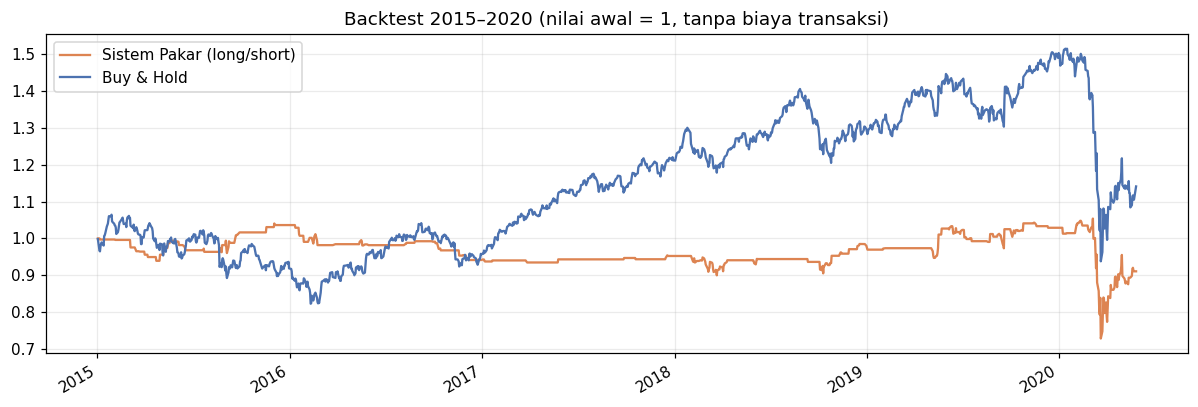

Return kumulatif  Sistem Pakar: -8.9%   |   Buy&Hold: +14.1%
Jumlah transaksi aktif: 254 dari 1311 hari


In [15]:
base = test.label.value_counts(normalize=True)
sig = []
for a in ["BUY","SELL"]:
    m = test.pred == a
    sig.append({"Sinyal": a, "Jumlah": int(m.sum()), "Precision sinyal": (test.label[m]==a).mean() if m.sum() else np.nan,
                "Peluang dasar": base[a], "Rata-rata return berikutnya": test.ret_next[m].mean() if m.sum() else np.nan})
display(pd.DataFrame(sig).round(4))

pos = test.pred.map({"BUY": 1, "SELL": -1, "HOLD": 0})
strat = (pos*test.ret_next).fillna(0)
bh    = test.ret_next.fillna(0)
eq = pd.DataFrame({"Sistem Pakar (long/short)": (1+strat).cumprod(), "Buy & Hold": (1+bh).cumprod()}); eq.index = test.Date.values
ax = eq.plot(figsize=(11, 3.8), color=["#DD8452","#4C72B0"]); ax.set_title(f"Backtest {test.Date.min().year}–{test.Date.max().year} (nilai awal = 1, tanpa biaya transaksi)"); ax.set_xlabel("")
plt.tight_layout(); plt.savefig("figs/backtest.png"); plt.show()
print(f"Return kumulatif  Sistem Pakar: {eq.iloc[-1,0]-1:+.1%}   |   Buy&Hold: {eq.iloc[-1,1]-1:+.1%}")
print(f"Jumlah transaksi aktif: {(pos!=0).sum()} dari {len(test)} hari")

### 6.3 Aturan mana yang paling sering aktif?

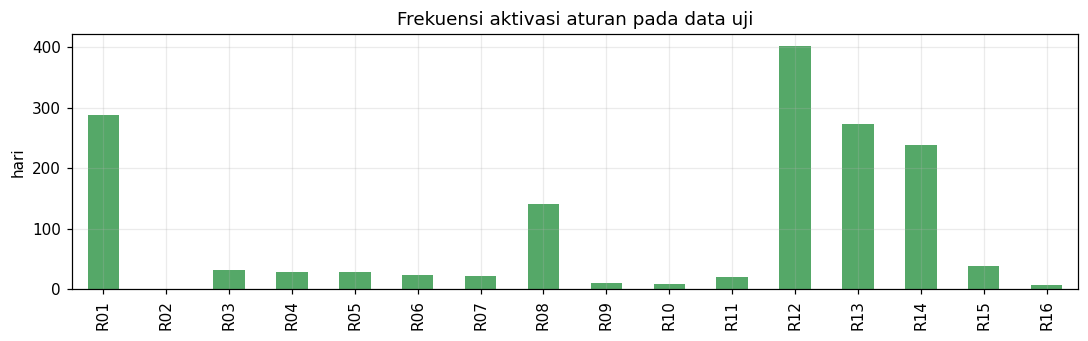

In [16]:
from collections import Counter
cnt = Counter(r[0] for f in test_fired for r in f)
freq = pd.Series(cnt).reindex([r[0] for r in RULES]).fillna(0).astype(int)
ax = freq.plot.bar(figsize=(10, 3.2), color="#55A868"); ax.set_title("Frekuensi aktivasi aturan pada data uji"); ax.set_ylabel("hari")
plt.tight_layout(); plt.savefig("figs/frekuensi_aturan.png"); plt.show()

### 6.4 Diagnostik aturan: data latih vs data uji (KB final)
Per aturan: berapa hari aktif dan seberapa sering aksinya benar, dibanding peluang dasar. Kolom data uji menunjukkan apakah keunggulan di data latih **bertahan di luar sampel** — berguna untuk pembahasan generalisasi di laporan.

In [17]:
base_tr = train.label.value_counts(normalize=True); base_te = test.label.value_counts(normalize=True)
fired_tr = [set(f[0] for f in infer(fuzzify(r))[2]) for _, r in train.iterrows()]
fired_te = [set(f[0] for f in infer(fuzzify(r))[2]) for _, r in test.iterrows()]
cf_now = {r[0]: r[4] for r in RULES}
rows = []
for rid, name, cond, act, c0, src_ in RULES_ORIG:
    mtr = np.array([rid in s for s in fired_tr]); mte = np.array([rid in s for s in fired_te])
    ptr = (train.label.values[mtr] == act).mean() if mtr.sum() else np.nan
    pte = (test.label.values[mte]  == act).mean() if mte.sum() else np.nan
    rows.append({"ID": rid, "Aturan": name, "Aksi": act, "CF awal": c0, "CF final": cf_now.get(rid, 0.0),
                 "n latih": int(mtr.sum()), "Presisi latih": ptr, "n uji": int(mte.sum()), "Presisi uji": pte,
                 "Dasar uji": base_te.get(act, 0.0)})
diag = pd.DataFrame(rows); diag["Keunggulan uji"] = (diag["Presisi uji"] - diag["Dasar uji"]).round(3)
display(diag.round(3))
# sebaran label linguistik (KB final) → cek apakah ambang fuzzifikasi wajar
F_tr = pd.DataFrame([fuzzify(r) for _, r in train.iterrows()])
for k in ["sent", "trend", "vol", "fear", "volume"]:
    print(f"{k:7s}:", F_tr[k].value_counts(normalize=True).round(3).to_dict())

,ID,Aturan,Aksi,CF awal,CF final,n latih,Presisi latih,n uji,Presisi uji,Dasar uji,Keunggulan uji
0,R01,Pasar tenang,HOLD,0.55,0.660,106,0.491,288,0.535,0.490,0.044
1,R02,Euforia + jenuh beli,SELL,0.30,0.300,14,0.357,0,NaN,0.233,NaN
2,R03,Pesimis + tren turun,SELL,0.35,0.420,41,0.537,32,0.281,0.233,0.048
3,R04,Kontrarian oversold,BUY,0.60,0.720,47,0.532,29,0.448,0.276,0.172
4,R05,Panik mereda,BUY,0.40,0.400,9,0.000,29,0.241,0.276,-0.035
5,R06,Volatilitas tinggi + turun,BUY,0.45,0.540,205,0.439,24,0.458,0.276,0.182
6,R07,Resesi ganda,SELL,0.55,0.550,42,0.286,22,0.318,0.233,0.085
7,R08,Pelonggaran moneter,BUY,0.40,0.400,345,0.391,140,0.279,0.276,0.002
8,R09,Inflasi + suku bunga naik,SELL,0.40,0.400,34,0.324,11,0.364,0.233,0.130
9,R10,Ekonomi & manufaktur +,BUY,0.45,0.225,55,0.273,9,0.222,0.276,-0.054


sent   : {'neutral': 0.6, 'pos': 0.15, 'neg': 0.15, 'very_neg': 0.05, 'very_pos': 0.05}
trend  : {'flat': 0.405, 'up': 0.303, 'down': 0.151, 'overextended': 0.092, 'oversold': 0.049}
vol    : {'normal': 0.784, 'high': 0.179, 'low': 0.036}
fear   : {'none': 0.946, 'high': 0.054}
volume : {'normal': 0.67, 'high': 0.33}


## 7. Test Case (minimum 20)
Setiap kasus = **skenario berita + kondisi harga** dengan **hasil yang diharapkan** (ditentukan dari desain knowledge base/logika pakar). Kasus ini berfungsi sebagai *regression test* untuk memastikan sistem berperilaku sesuai desain, bukan untuk mengukur akurasi prediksi pasar.

Untuk realisme, tiap skenario ditambah 3 headline netral (satu hari nyata memuat banyak headline tanpa sentimen kuat).

> **Catatan setelah kalibrasi:** kolom *Diharapkan* mengikuti **desain pakar awal**. Tabel menampilkan hasil **KB awal** dan **KB final** berdampingan. Bila KB final menurunkan/menonaktifkan CF aturan yang tidak didukung data India, hasil sebuah kasus bisa berbeda dari ekspektasi — itu efek kalibrasi (bukan bug), dan dijelaskan di bawah tabel.

In [18]:
FILLER = ["Investors watch earnings calendar this week", "Trading volume steady in afternoon session", "Analysts review quarterly reports"]

def make_facts(headlines, trend=0.0, vol=0.01, prev_sent=0.0, filler=True):
    """Bangun fakta numerik dari daftar headline + kondisi harga (trend vs MA20, volatilitas, rata-rata sentimen sebelumnya)."""
    hs = list(headlines) + (FILLER if (filler and headlines) else [])
    ov, asp, fear = [], {a: [] for a in ASPECTS}, 0
    for t in hs:
        o, a = headline_sentiment(t); ov.append(o)
        for k, v in a.items(): asp[k].append(v)
        if any(LEXICON.get(w, 0) <= -.7 for w in preprocess(t)): fear += 1
    m = lambda v: float(np.mean(v)) if v else 0.0
    s = m(ov)
    f = {'n': len(hs), 'sent_ma3': s, 'sent_delta': s-prev_sent, 'trend': trend, 'vol': vol, 'fear': fear/len(hs) if hs else 0.0}
    for k, v in asp.items(): f['a_'+k] = m(v)
    f['econ'] = float(np.mean([f['a_economy'], f['a_unemployment'], f['a_manufacturing'], f['a_inflation']]))
    f['fin']  = float(np.mean([f['a_financial'], f['a_monetary']]))
    return f

def advise(headlines, trend=0.0, vol=0.01, prev_sent=0.0, verbose=True):
    """Fungsi utama: headline + kondisi harga → rekomendasi + penjelasan."""
    f = make_facts(headlines, trend, vol, prev_sent); F = fuzzify(f); dec, cf, fired = infer(F)
    if verbose:
        print("="*70); print("Headline :", *(headlines or ["(tidak ada)"]), sep="\n   • ")
        print(f"Kondisi  : tren vs MA20 = {trend:+.1%}, volatilitas = {vol:.3f}, sentimen sebelumnya = {prev_sent:+.2f}")
        print("Fakta    :", F)
        print("Aturan aktif:"); [print(f"   {r[0]} {r[1]:<28} → {r[2]:<4} (CF {r[3]})") for r in fired] or print("   (tidak ada)")
        print("CF total :", {k: round(v, 2) for k, v in cf.items()})
        print(f"\n>>> REKOMENDASI: {dec}")
    return dec, cf, fired, F

# (id, deskripsi, headline, trend, vol, prev_sent, ekspektasi, alasan)
TEST_CASES = [
 ("TC01","Pasar tenang, berita netral",                ["Stocks little changed ahead of jobs data"],                                              0.00, 0.004,  0.00,"HOLD","R01 pasar tenang"),
 ("TC02","Panik + harga jatuh dalam (oversold)",       ["Stocks plunge as fears of recession grow","Wall Street tumbles on worst selloff in months"],-0.09, 0.020,  0.00,"BUY", "R04/R06 kontrarian"),
 ("TC03","Ekonomi & sektor keuangan sama-sama negatif",["Economy shrinks as banks report heavy losses","Bank lending falls sharply, economic growth slows"],-0.01,0.012, 0.00,"SELL","R07 resesi ganda"),
 ("TC04","Bank sentral menurunkan suku bunga",         ["Fed cuts rates to boost economy","Central bank easing lifts stocks"],                    0.01, 0.010,  0.00,"BUY", "R08 pelonggaran moneter"),
 ("TC05","Inflasi tinggi + kenaikan suku bunga",       ["Inflation is not easing as Fed hikes rates","Rising prices force central bank to raise rates"],0.00,0.010, 0.00,"SELL","R09 inflasi+bunga"),
 ("TC06","Ekonomi & manufaktur kuat",                  ["Economy grows strongly as manufacturing output rises","Factory production jumps, economic growth robust"],0.01,0.010,0.00,"BUY","R10 ekspansi riil"),
 ("TC07","PHK massal & pengangguran naik",             ["Layoffs surge as unemployment rises","Job losses mount, jobless claims jump"],           -0.01, 0.010,  0.00,"SELL","R11 tenaga kerja negatif"),
 ("TC08","Euforia, harga jenuh beli → jangan mengejar",["Stocks soar to record high as bulls cheer","Markets surge on booming profits"],              0.07, 0.012,  0.00,"HOLD","R15 (>R02) tidak kejar momentum"),
 ("TC09","Tidak ada berita sama sekali",               [],                                                                                       0.00, 0.010,  0.00,"HOLD","R12/R16 informasi kurang"),
 ("TC10","Panik mereda setelah crash",                 ["Stocks rebound as fears ease after crash","Panic subsides, markets recover"],            -0.03, 0.015, -0.15,"BUY", "R05 panik mereda"),
 ("TC11","Volatilitas tinggi & tren turun",            ["Stocks swing wildly as investors weigh data"],                                           -0.03, 0.022,  0.00,"BUY", "R06 capitulation"),
 ("TC12","Tren naik tenang, sentimen positif",         ["Stocks edge higher"],                                                                    0.03, 0.005,  0.00,"HOLD","R01/R14/R15"),
 ("TC13","Sentimen positif, harga datar (tanpa aturan cocok)",["Stocks gain on upbeat earnings"],                                                 0.00, 0.010,  0.00,"HOLD","default HOLD"),
 ("TC14","Crash headline, harga belum turun dalam",    ["Stocks crash in worst rout since 2008","Panic selling wipes out trillions"],             -0.01, 0.015,  0.00,"BUY", "R13 kontrarian"),
 ("TC15","Sinyal bertentangan (R03 SELL vs R13 BUY)",  ["Stocks slide as worries grow","Wall Street falls on weak data"],                         -0.03, 0.012,  0.02,"HOLD","conflict resolution → HOLD"),
 ("TC16","Pelonggaran moneter tapi harga jenuh beli",  ["Fed cuts rates as economy weakens"],                                                      0.06, 0.010,  0.00,"HOLD","R08 diblokir jenuh beli"),
 ("TC17","Krisis keuangan + resesi",                   ["Economy slips into recession as banks fail","Financial crisis deepens, economic outlook grim"],-0.01,0.012,0.00,"SELL","R07 unggul atas R13"),
 ("TC18","Rally berita bagus, tren naik",              ["Wall Street rallies on strong jobs report","Stocks climb as hopes rise for more stimulus"],0.02,0.011,-0.02,"HOLD","R14/R15 tidak kejar momentum"),
 ("TC19","Pesimis ringan, memburuk, tren turun",       ["Dow drops as investors worry about slowing growth"],                                     -0.025,0.014,  0.03,"SELL","R03 pesimis + tren turun"),
 ("TC20","Berita campur, menunggu keputusan Fed",      ["Stocks mixed as investors await Fed decision","Markets quiet before earnings"],           0.00, 0.011,  0.00,"HOLD","R12 netral & datar"),
]

def run_cases(cases, cfg):
    def go():
        out = []
        for tid, desc, hl, tr, vo, ps, exp, why in cases:
            dec, cf, fired, F = advise(hl, tr, vo, ps, verbose=False); out.append((dec, cf, fired))
        return out
    return _with_kb(cfg, go)

res_f, res_o = run_cases(TEST_CASES, FINAL_KB), run_cases(TEST_CASES, ORIG_KB)
rows = []
for (tid, desc, hl, tr, vo, ps, exp, why), (dec, cf, fired), (dec_o, _, _) in zip(TEST_CASES, res_f, res_o):
    rows.append({"ID": tid, "Skenario": desc, "Diharapkan": exp, "Hasil (KB awal)": dec_o, "Hasil (KB final)": dec,
                 "Aturan aktif (final)": ",".join(r[0] for r in fired) or "-",
                 "CF (B/S/H)": "/".join(f"{cf[k]:.2f}" for k in ("BUY","SELL","HOLD")), "Status": "✅ LULUS" if dec == exp else "❌ BEDA"})
tc = pd.DataFrame(rows); display(tc)
n_pass_final = int((tc.Status.str.contains("LULUS")).sum()); n_pass_orig = int((tc["Hasil (KB awal)"] == tc["Diharapkan"]).sum())
print(f"\nKB awal : {n_pass_orig}/{len(tc)} sesuai ekspektasi | KB final: {n_pass_final}/{len(tc)} sesuai ekspektasi")
for _, r in tc[tc.Status.str.contains("BEDA")].iterrows():
    print(f"  {r.ID} ({r.Skenario}): diharapkan {r.Diharapkan}, KB final → {r['Hasil (KB final)']} [aturan aktif: {r['Aturan aktif (final)']}]")
assert len(TEST_CASES) >= 20
assert n_pass_orig == len(TEST_CASES), "Regresi pada KB awal: mesin inferensi tidak lagi sesuai desain"

,ID,Skenario,Diharapkan,Hasil (KB awal),Hasil (KB final),Aturan aktif (final),CF (B/S/H),Status
0,TC01,"Pasar tenang, berita netral",HOLD,HOLD,HOLD,"R01,R12",0.00/0.00/0.81,✅ LULUS
1,TC02,Panik + harga jatuh dalam (oversold),BUY,BUY,BUY,"R04,R06,R13",0.92/0.00/0.00,✅ LULUS
2,TC03,Ekonomi & sektor keuangan sama-sama negatif,SELL,SELL,SELL,"R07,R13",0.35/0.55/0.00,✅ LULUS
3,TC04,Bank sentral menurunkan suku bunga,BUY,BUY,BUY,R08,0.40/0.00/0.00,✅ LULUS
4,TC05,Inflasi tinggi + kenaikan suku bunga,SELL,SELL,SELL,"R07,R09,R13",0.35/0.73/0.00,✅ LULUS
5,TC06,Ekonomi & manufaktur kuat,BUY,BUY,HOLD,R10,0.23/0.00/0.00,❌ BEDA
6,TC07,PHK massal & pengangguran naik,SELL,SELL,SELL,"R11,R13",0.35/0.55/0.00,✅ LULUS
7,TC08,"Euforia, harga jenuh beli → jangan mengejar",HOLD,HOLD,HOLD,"R02,R15",0.00/0.30/0.45,✅ LULUS
8,TC09,Tidak ada berita sama sekali,HOLD,HOLD,HOLD,"R12,R16",0.00/0.00/0.59,✅ LULUS
9,TC10,Panik mereda setelah crash,BUY,BUY,BUY,"R05,R13",0.61/0.00/0.00,✅ LULUS



KB awal : 20/20 sesuai ekspektasi | KB final: 18/20 sesuai ekspektasi
  TC06 (Ekonomi & manufaktur kuat): diharapkan BUY, KB final → HOLD [aturan aktif: R10]
  TC19 (Pesimis ringan, memburuk, tren turun): diharapkan SELL, KB final → HOLD [aturan aktif: R03,R13]


### Test case tambahan konteks India (bonus, di luar 20 test case utama)
Skenario berbahasa/istilah India untuk memastikan token RBI/repo/Sensex/NPA terbaca dengan benar oleh modul FiGAS. Ekspektasi mengikuti aturan yang sama (R04, R08, R09, R07).

In [19]:
INDIA_TEST_CASES = [
 ("IN01","RBI memangkas repo rate",           ["RBI cuts repo rate by 25 bps to boost growth","Reserve Bank of India eases liquidity, stocks rally"], 0.01, 0.010, 0.0, "BUY",  "R08 pelonggaran moneter"),
 ("IN02","RBI menaikkan repo rate + inflasi", ["RBI hikes repo rate as inflation worries mount","Rising prices push Reserve Bank to tighten"],       0.00, 0.010, 0.0, "SELL", "R09 inflasi+bunga"),
 ("IN03","Sensex anjlok, oversold",          ["Sensex plunges as FII outflows spark panic selling","Nifty tumbles on worst crash in months"],        -0.09, 0.020, 0.0, "BUY",  "R04/R06 kontrarian"),
 ("IN04","Ekonomi & bank sama-sama negatif", ["Economy shrinks as recession fears grow, GDP falls sharply","Banks report heavy losses as bad loans surge, bank lending falls sharply"],            -0.01, 0.012, 0.0, "SELL", "R07 resesi ganda"),
]
rows = []
for tid, desc, hl, tr, vo, ps, exp, why in INDIA_TEST_CASES:
    dec, cf, fired, F = advise(hl, tr, vo, ps, verbose=False)
    rows.append({"ID": tid, "Skenario": desc, "Diharapkan": exp, "Hasil": dec, "Aturan aktif": ",".join(r[0] for r in fired) or "-", "Status": "✅ LULUS" if dec == exp else "❌ GAGAL"})
tc_in = pd.DataFrame(rows); display(tc_in)
print(f"Test case India (bonus): {(tc_in.Status.str.contains('LULUS')).sum()}/{len(tc_in)} lulus")

,ID,Skenario,Diharapkan,Hasil,Aturan aktif,Status
0,IN01,RBI memangkas repo rate,BUY,BUY,R08,✅ LULUS
1,IN02,RBI menaikkan repo rate + inflasi,SELL,SELL,"R07,R09,R13",✅ LULUS
2,IN03,"Sensex anjlok, oversold",BUY,BUY,"R04,R06,R13",✅ LULUS
3,IN04,Ekonomi & bank sama-sama negatif,SELL,SELL,"R07,R13",✅ LULUS


Test case India (bonus): 4/4 lulus


### 7.1 Unit test komponen sentimen (bonus)
Memastikan modul NLP (negasi, intensifier, pembalikan polaritas, aspek) bekerja benar.

In [20]:
unit_tests = [
 ("Fed cuts rates",                                  lambda o,a: o > 0,                      "'rate cut' bernilai positif"),
 ("Fed does not cut rates",                          lambda o,a: o < headline_sentiment("Fed cuts rates")[0], "negasi menurunkan skor"),
 ("Stocks fall",                                     lambda o,a: o < 0,                      "kata negatif → negatif"),
 ("Stocks fall sharply",                             lambda o,a: o < headline_sentiment("Stocks fall")[0], "intensifier memperkuat"),
 ("Stocks fall slightly",                            lambda o,a: o > headline_sentiment("Stocks fall")[0], "dampener memperlemah"),
 ("Unemployment falls sharply",                      lambda o,a: o > 0 and a['unemployment'] > 0, "pengangguran turun = positif (polaritas dibalik)"),
 ("Inflation rises to worrying levels",              lambda o,a: a['inflation'] < 0,         "inflasi naik = negatif"),
 ("The company opened a new office",                 lambda o,a: o == 0,                     "tanpa kata sentimen → 0"),
]
res = []
for h, cond, note in unit_tests:
    o, a = headline_sentiment(h); res.append({"Headline": h, "Skor": round(o, 3), "Uji": note, "Status": "✅" if cond(o, a) else "❌"})
display(pd.DataFrame(res)); assert all(r["Status"] == "✅" for r in res)

unit_tests_in = [
 ("RBI cuts repo rate",                              lambda o,a: o > 0 and a.get('monetary', 0) > 0, "'repo rate cut' positif & terbaca sebagai aspek moneter (RBI/repo)"),
 ("Reserve Bank of India hikes repo rate",           lambda o,a: o < 0 and a.get('monetary', 0) < 0, "'repo rate hike' negatif pada aspek moneter"),
 ("Sensex plunges as NPA worries grow",              lambda o,a: o < 0 and a.get('market', 0) < 0,   "Sensex = token pasar; plunge/NPA/worries negatif"),
]
res_in = []
for h, cond, note in unit_tests_in:
    o, a = headline_sentiment(h); res_in.append({"Teks": h, "Skor": round(o, 3), "Uji": note, "Status": "✅" if cond(o, a) else "❌"})
display(pd.DataFrame(res_in)); assert all(r["Status"] == "✅" for r in res_in)

,Headline,Skor,Uji,Status
0,Fed cuts rates,0.354,'rate cut' bernilai positif,✅
1,Fed does not cut rates,-0.200,negasi menurunkan skor,✅
2,Stocks fall,-0.354,kata negatif → negatif,✅
3,Stocks fall sharply,-0.433,intensifier memperkuat,✅
4,Stocks fall slightly,-0.173,dampener memperlemah,✅
5,Unemployment falls sharply,0.433,pengangguran turun = positif (polaritas dibalik),✅
6,Inflation rises to worrying levels,-0.179,inflasi naik = negatif,✅
7,The company opened a new office,0.000,tanpa kata sentimen → 0,✅


,Teks,Skor,Uji,Status
0,RBI cuts repo rate,0.354,'repo rate cut' positif & terbaca sebagai aspek moneter (RBI/repo),✅
1,Reserve Bank of India hikes repo rate,-0.354,'repo rate hike' negatif pada aspek moneter,✅
2,Sensex plunges as NPA worries grow,-0.694,Sensex = token pasar; plunge/NPA/worries negatif,✅


## 8. Demo: Coba Sendiri
Ubah headline / kondisi harga lalu jalankan. `trend` = harga vs rata-rata 20 hari (0.05 = 5% di atas), `vol` = volatilitas harian, `prev_sent` = rata-rata sentimen beberapa hari sebelumnya.

In [21]:
_ = advise(["Fed signals rate cut as inflation cools", "Wall Street rallies on strong jobs report"], trend=0.01, vol=0.010, prev_sent=0.0)

Headline :
   • Fed signals rate cut as inflation cools
   • Wall Street rallies on strong jobs report
Kondisi  : tren vs MA20 = +1.0%, volatilitas = 0.010, sentimen sebelumnya = +0.00
Fakta    : {'sent': 'very_pos', 'delta': 'improving', 'trend': 'flat', 'vol': 'normal', 'fear': 'none', 'econ': 'pos', 'fin': 'pos', 'mon': 'pos', 'infl': 'pos', 'unemp': 'pos', 'manuf': 'none', 'volume': 'normal'}
Aturan aktif:
   R08 Pelonggaran moneter          → BUY  (CF 0.4)
CF total : {'BUY': 0.4, 'SELL': 0.0, 'HOLD': 0.0}

>>> REKOMENDASI: BUY


In [22]:
_ = advise(["Inflation jumps as Fed raises rates again", "Rising prices squeeze consumers and factories"], trend=0.0, vol=0.010, prev_sent=0.0)

Headline :
   • Inflation jumps as Fed raises rates again
   • Rising prices squeeze consumers and factories
Kondisi  : tren vs MA20 = +0.0%, volatilitas = 0.010, sentimen sebelumnya = +0.00
Fakta    : {'sent': 'very_neg', 'delta': 'deteriorating', 'trend': 'flat', 'vol': 'normal', 'fear': 'none', 'econ': 'neg', 'fin': 'neg', 'mon': 'neg', 'infl': 'neg', 'unemp': 'none', 'manuf': 'none', 'volume': 'normal'}
Aturan aktif:
   R07 Resesi ganda                 → SELL (CF 0.55)
   R09 Inflasi + suku bunga naik    → SELL (CF 0.4)
   R13 Sentimen sangat negatif      → BUY  (CF 0.35)
CF total : {'BUY': 0.35, 'SELL': 0.73, 'HOLD': 0.0}

>>> REKOMENDASI: SELL


### 8.1 Demo pada tanggal nyata di dataset
Menjalankan sistem pakar pada satu hari tertentu, lalu membandingkan dengan pergerakan aktual harga berikutnya (krisis 2008, demonetisasi 2016, crash COVID-19 2020).

In [23]:
def advise_date(date):
    d0 = pd.Timestamp(date); row = daily.iloc[(daily.Date - d0).abs().argmin()]
    print(f"Hari bursa terdekat di data: {row.Date.date()} | {INDEX_TICKER} = {row.cp:.2f} | jumlah artikel = {int(row.n)}")
    print("Contoh judul berita hari itu:"); [print("   •", t) for t in df[df.TDate == row.Date].Title.head(4)]
    F = fuzzify(row); dec, cf, fired = infer(F)
    print("Fakta:", F); print("Aturan aktif:", [(r[0], r[1], r[2]) for r in fired])
    print(f"CF: { {k: round(v,2) for k,v in cf.items()} }  →  REKOMENDASI: {dec}")
    if pd.notna(row.ret_next): print(f"Aktual: return berikutnya = {row.ret_next:+.2%}  (label {row.label})")

for dt in ["2008-10-24", "2016-11-09", "2020-03-23"]:
    advise_date(dt); print("-"*80)

Hari bursa terdekat di data: 2008-10-24 | ^BSESN = 8701.07 | jumlah artikel = 32
Contoh judul berita hari itu:
   • RBI concerned over high commodity prices
   • Capital flows decline in volatile markets
   • Centre, state finances in the pink of health
   • Global banks lend less to Indian peers, firms in Q2: BIS
Fakta: {'sent': 'neutral', 'delta': 'stable', 'trend': 'oversold', 'vol': 'high', 'fear': 'none', 'econ': 'none', 'fin': 'none', 'mon': 'none', 'infl': 'none', 'unemp': 'none', 'manuf': 'none', 'volume': 'high'}
Aturan aktif: [('R06', 'Volatilitas tinggi + turun', 'BUY')]
CF: {'BUY': 0.54, 'SELL': 0.0, 'HOLD': 0.0}  →  REKOMENDASI: BUY
Aktual: return berikutnya = -2.20%  (label SELL)
--------------------------------------------------------------------------------
Hari bursa terdekat di data: 2016-11-09 | ^BSESN = 27252.53 | jumlah artikel = 13
Contoh judul berita hari itu:
   • UCO Bank posts net loss of Rs 384.83 crore
   • RBI may have to change policy course
   • Rs 500, R

## 9. Kesimpulan, Keterbatasan & Rencana Perbaikan

**Temuan utama** – angka dihitung otomatis dari hasil run Anda (sel di bawah), bukan ditulis tangan, agar laporan konsisten dengan keluaran sebenarnya.

**Keterbatasan**
1. Dataset berisi **judul + ringkasan singkat** (bukan isi artikel penuh) dan **tidak merata** antar tahun; pada sebagian artikel (±2.000, terutama 2003) deskripsi kosong/identik dengan judul sehingga hanya judul yang dipakai. Rentang berhenti **Mei 2020**: data uji ±1.300 hari (2015–Mei 2020) dan didominasi satu rezim (termasuk crash COVID-19).
2. Kamus sentimen dibuat manual (±243 kata/frasa, termasuk istilah India), belum divalidasi anotator seperti paper 1. Aspek memakai jendela kata, bukan dependency parsing.
3. **Kalibrasi ulang bersifat sederhana:** ambang sentimen dari persentil data latih dan CF disesuaikan dengan uji lift hanya untuk aturan dengan n ≥ 30; keputusan memakainya didasarkan pada satu jendela validasi (2012–2014) yang kecil sehingga keputusannya sendiri bisa berisik. Aturan yang jarang aktif (n < 30) tetap memakai CF pakar dan belum teruji.
4. **Pergeseran distribusi sentimen:** dengan ambang dari persentil data latih, proporsi hari `very_neg` pada data uji bisa jauh lebih tinggi daripada pada data latih (lihat 6.0b) sehingga aturan seperti R13 lebih sering aktif di data uji. Ini kemungkinan pergeseran gaya teks/berita antar periode (bukan sekadar pergerakan pasar) dan perlu dibahas sebagai keterbatasan generalisasi.
5. Berita dipasangkan ke hari bursa pertama pada/setelah tanggal terbit; jam terbit tidak diketahui. Backtest tanpa biaya transaksi/slippage dan memakai indeks, bukan instrumen yang bisa diperdagangkan.
6. Harga bergantung pada Yahoo Finance (`yfinance`) – data bisa direvisi antar waktu unduh.
7. **Bukan saran investasi.**

**Pengembangan lanjutan:** *walk-forward validation* (beberapa jendela uji), kamus lebih besar (Loughran-McDonald / FinBERT), dependency parsing spaCy sesuai FiGAS, data berita lebih baru (2020+), variabel makro India (repo rate, INR/USD, yield 10Y, harga minyak) seperti referensi 2.

In [24]:
# ---- Ringkasan otomatis hasil run (angka dihitung dari variabel di atas) ----
acc_es  = accuracy_score(test.label, test.pred)
maj_te = test.label.mode()[0]
acc_bl  = (test.label == maj_te).mean()          # baseline konstanta terkuat pada data uji
best_ml = cmp_df[cmp_df.Model.isin(list(models))].sort_values("Accuracy", ascending=False).iloc[0]
rel = "di atas" if acc_es > acc_bl + 0.01 else "di bawah" if acc_es < acc_bl - 0.01 else "setara dengan"
print(f"• Data uji {test.Date.min().date()} → {test.Date.max().date()} ({len(test)} hari bursa berberita), indeks {INDEX_TICKER}.")
print(f"• Akurasi sistem pakar = {acc_es:.3f}, {rel} baseline terkuat 'selalu {maj_te}' ({acc_bl:.3f}). Macro-F1 = {cmp_df.iloc[2]['Macro-F1']:.3f}.")
se = float(np.sqrt(acc_bl*(1-acc_bl)/len(test)))
print(f"• Kalibrasi ulang KB: {'DIPAKAI' if adopt else 'DITOLAK oleh validasi (KB awal dipertahankan)'} | macro-F1 validasi awal {cmp_val.iloc[0]['macroF1']:.3f} vs terkalibrasi {cmp_val.iloc[1]['macroF1']:.3f}.")
print(f"• Akurasi sistem pakar KB awal (tanpa kalibrasi) pada data uji: {cmp_df.iloc[3]['Accuracy']:.3f}.")
print(f"• Galat baku akurasi pada n={len(test)} ≈ ±{se:.3f}: selisih akurasi < ±{2*se:.3f} antar model TIDAK bermakna secara statistik.")
print(f"• Model ML terbaik: {best_ml['Model']} (akurasi {best_ml['Accuracy']:.3f}, macro-F1 {best_ml['Macro-F1']:.3f}).")
for a in ["BUY", "SELL"]:
    m = test.pred == a
    if m.sum(): print(f"• Sinyal {a}: {int(m.sum())} hari, precision {(test.label[m]==a).mean():.3f} vs peluang dasar {base[a]:.3f}.")
print(f"• Backtest long/short: sistem pakar {eq.iloc[-1,0]-1:+.1%} vs Buy&Hold {eq.iloc[-1,1]-1:+.1%} (tanpa biaya transaksi).")
print(f"• Test case: KB awal {n_pass_orig}/{len(tc)} dan KB final {n_pass_final}/{len(tc)} sesuai ekspektasi (+ bonus India KB final {(tc_in.Status.str.contains('LULUS')).sum()}/{len(tc_in)}).")
print(f"• Korelasi sentimen(MA3) vs return BERIKUTNYA: {daily.sent_ma3.corr(daily.ret_next):+.3f} (kecil = pasar sulit diprediksi dari berita saja).")

• Data uji 2015-01-02 → 2020-05-26 (1311 hari bursa berberita), indeks ^BSESN.
• Akurasi sistem pakar = 0.465, di bawah baseline terkuat 'selalu HOLD' (0.490). Macro-F1 = 0.296.
• Kalibrasi ulang KB: DIPAKAI | macro-F1 validasi awal 0.246 vs terkalibrasi 0.285.
• Akurasi sistem pakar KB awal (tanpa kalibrasi) pada data uji: 0.485.
• Galat baku akurasi pada n=1311 ≈ ±0.014: selisih akurasi < ±0.028 antar model TIDAK bermakna secara statistik.
• Model ML terbaik: Logistic Regression (akurasi 0.490, macro-F1 0.374).
• Sinyal BUY: 222 hari, precision 0.306 vs peluang dasar 0.276.
• Sinyal SELL: 32 hari, precision 0.125 vs peluang dasar 0.233.
• Backtest long/short: sistem pakar -8.9% vs Buy&Hold +14.1% (tanpa biaya transaksi).
• Test case: KB awal 20/20 dan KB final 18/20 sesuai ekspektasi (+ bonus India KB final 4/4).
• Korelasi sentimen(MA3) vs return BERIKUTNYA: +0.007 (kecil = pasar sulit diprediksi dari berita saja).


In [25]:
# Simpan ringkasan hasil untuk laporan
kb_table.to_csv("knowledge_base_rules.csv", index=False)        # KB awal
kb_final.to_csv("knowledge_base_final.csv", index=False)           # KB setelah kalibrasi (6.0)
rule_calibration.to_csv("kalibrasi_aturan.csv", index=False)
tc.to_csv("hasil_test_case.csv", index=False)
tc_in.to_csv("hasil_test_case_india.csv", index=False)
diag.to_csv("diagnostik_aturan_train.csv", index=False)
daily.to_csv("fitur_harian_india.csv", index=False)
cmp_df.to_csv("perbandingan_model.csv", index=False)
print("Tersimpan: knowledge_base_rules.csv, knowledge_base_final.csv, kalibrasi_aturan.csv, hasil_test_case.csv, perbandingan_model.csv, hasil_test_case_india.csv, diagnostik_aturan_train.csv, fitur_harian_india.csv, folder figs/ (diagram & grafik)")

Tersimpan: knowledge_base_rules.csv, knowledge_base_final.csv, kalibrasi_aturan.csv, hasil_test_case.csv, perbandingan_model.csv, hasil_test_case_india.csv, diagnostik_aturan_train.csv, fitur_harian_india.csv, folder figs/ (diagram & grafik)
